# Tender Award Outcome Prediction and Affirmative-Action Fairness Auditing

**Emmanuel Bett (131611)** · Supervisor: Dr. John Olukuru · Institute of Mathematical Sciences, Strathmore University

This notebook implements the methodology of the research proposal step by step, following CRISP-DM:

| Phase | Section | Proposal objective |
|---|---|---|
| Business understanding | 1 | – |
| Data understanding | 2 | – |
| Data preparation | 3 (outcome taxonomy, definitions, features, exploration) | (i) |
| Modelling | 4 (five model families, forward-chaining temporal validation) | (ii) |
| Evaluation | 5 (metrics, bootstrap CIs, DeLong and McNemar tests, sensitivity) | (ii) |
| Interpretation | 6 (TreeSHAP attributions) | (iii) |
| Fairness audit | 7 (independence, separation, sufficiency for AGPO status and county) | (iv) |
| Deployment | 8 (saved model bundle and scoring function) | – |

The earlier exploratory notebook (`Tender_Award_Prediction.ipynb`) is kept unchanged for reference. It used a binary
"contract exists" label and a random train–test split; this notebook replaces both, as the proposal requires.

In [1]:
import json
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from scipy.stats import chi2, chi2_contingency, norm, rankdata, spearmanr
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import (HistGradientBoostingClassifier, RandomForestClassifier,
                              StackingClassifier)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (PredefinedSplit, RandomizedSearchCV, StratifiedKFold,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.contingency_tables import mcnemar
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- configuration -----------------------------
SEED = 42
DATA_DIR = Path("data")
OUT_DIR = Path("outputs/award_notebook")
FIG_DIR = OUT_DIR / "figures"
MODEL_DIR = Path("models/award_risk_v2")
for d in (OUT_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

YEARS = (2018, 2024)              # analysis window (over 99% of portal records)
TUNE_TRAIN_YEARS = [2018, 2019]   # hyperparameter tuning: fit on these ...
TUNE_VAL_YEAR = 2020              # ... validate on this (precedes every test year)
TEST_YEARS = [2021, 2022, 2023, 2024]
PRIMARY_DEF = "D2"                # pre-specified primary outcome definition (Section 3.3)
N_ITER = 10                       # randomised-search iterations per model
N_BOOT = 1000                     # bootstrap resamples for confidence intervals
FAST = False                      # True = 15% subsample for a quick dry run

NAVY, RED, GREY = "#002D62", "#C8102E", "#9AA5B1"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


print("Run started", datetime.now().strftime("%Y-%m-%d %H:%M"), "| FAST =", FAST)

Run started 2026-11-05 11:35 | FAST = False


## 1. Business Understanding

**Decision problem.** Given the characteristics of a tender that are observable *at or before its closing date*,
estimate the probability that it will proceed to contract award, and express this as a risk score a procuring entity
can act on while correction is still possible (for example by extending the bidding window or revising the
specification).

**Success criteria** (from the proposal): predictive performance that is (a) stable under forward-chaining temporal
validation and (b) equitable across AGPO categories and counties.

**Scoring point.** Because the score is meant to be used at the closing date, a feature is admissible only if it is
known by then. Bid records are opened at or after closing, and contract records exist only after award, so neither
may be used as a predictor.

## 2. Data Understanding

The research instrument is a MariaDB 10.6 dump of the PPIP database (`migrated_ppip_at_4_dec.sql`, 679 MB). This
section reads the dump directly, checks that the CSV extracts used in the rest of the notebook are faithful to it,
and then profiles the export for coverage, timing, missingness and temporal span, as the proposal requires. Each
finding ends with its consequence for data preparation, and Section 2.9 collects them.

### 2.1 Reading the SQL dump

No database server is needed. The dump is streamed line by line: each `CREATE TABLE` statement gives a table's
columns, types and foreign keys, and each `INSERT` statement is tokenised into rows. TIMESTAMP columns are written in
UTC (the dump sets `TIME_ZONE='+00:00'`), so they are shifted to East Africa Time (UTC+3, no daylight saving), the
clock on which procuring entities set publication and closing times. DATE columns carry no time zone and are left
unchanged. Parsing takes about a minute.

In [2]:
import re

DUMP = Path("migrated_ppip_at_4_dec.sql")
DERIVED_CSVS = {"final_modeling_data", "prepared_tenders"}  # outputs of the earlier notebook, not dump extracts
EXTRA_TABLES = ["documents", "document_types", "tender_team_members", "team_types", "submission_method_tender",
                "submission_methods", "framework_agreement_type_tender", "tender_subscribers", "audits"]
EAT = pd.Timedelta(hours=3)
NUMERIC_TYPES = {"tinyint", "smallint", "mediumint", "int", "bigint", "decimal", "double", "float"}

_CREATE = re.compile(r"^CREATE TABLE `(\w+)` \(")
_COLUMN = re.compile(r"^\s+`(\w+)` (\w+)")
_FOREIGN = re.compile(r"FOREIGN KEY \(`\w+`\) REFERENCES `(\w+)`")
_INSERT = re.compile(r"^INSERT INTO `(\w+)` VALUES \(")
_TOKEN = re.compile(r"'((?:[^'\\]|\\.)*)'|(NULL)|([^,()']+)|(\),\(|\);?$)", re.S)
_ESCAPE = re.compile(r"\\(.)", re.S)
_ESCAPES = {"0": "\0", "n": "\n", "r": "\r", "t": "\t", "Z": "\x1a", "b": "\b"}


def _unescape(s):
    return _ESCAPE.sub(lambda e: _ESCAPES.get(e.group(1), e.group(1)), s) if "\\" in s else s


def parse_dump(path, keep):
    """Stream a mysqldump file. Return every table's schema and row count, and the raw rows of the tables in `keep`."""
    schema, counts, rows, current = {}, {}, {t: [] for t in keep}, None
    with open(path, encoding="utf8", errors="replace") as f:
        for line in f:
            if m := _INSERT.match(line):
                table, sink, row, n = m.group(1), rows.get(m.group(1)), [], 0
                for quoted, null, bare, end in _TOKEN.findall(line.rstrip("\n"), m.end()):
                    if end:
                        n += 1
                        if sink is not None:
                            sink.append(row)
                        row = []
                    elif null:
                        row.append(None)
                    elif bare:
                        row.append(bare)
                    else:
                        row.append(_unescape(quoted))
                counts[table] = counts.get(table, 0) + n
            elif m := _CREATE.match(line):
                current = schema[m.group(1)] = {"columns": [], "types": [], "refs": set()}
            elif current is not None:
                if line.startswith(")"):
                    current = None
                elif fk := _FOREIGN.search(line):
                    current["refs"].add(fk.group(1))
                elif col := _COLUMN.match(line):
                    current["columns"].append(col.group(1))
                    current["types"].append(col.group(2))
    return schema, counts, rows


def to_frame(rows, columns, types):
    """Build a typed DataFrame: numbers as numbers, TIMESTAMPs converted from UTC to EAT, DATEs as dates."""
    df = pd.DataFrame(rows, columns=columns)
    for col, typ in zip(columns, types):
        if typ in NUMERIC_TYPES:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        elif typ in ("timestamp", "datetime"):
            df[col] = pd.to_datetime(df[col], format="%Y-%m-%d %H:%M:%S", errors="coerce")
            if typ == "timestamp":
                df[col] += EAT
        elif typ == "date":
            df[col] = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
    return df


t0 = time.time()
csv_tables = sorted(p.stem for p in DATA_DIR.glob("*.csv") if p.stem not in DERIVED_CSVS)
schema, row_counts, raw = parse_dump(DUMP, csv_tables + EXTRA_TABLES)
ragged = {t: sum(len(r) != len(schema[t]["columns"]) for r in rs) for t, rs in raw.items()}
assert not any(ragged.values()), f"rows whose width differs from the schema: {ragged}"
db = {t: to_frame(rs, schema[t]["columns"], schema[t]["types"]) for t, rs in raw.items()}
del raw
print(f"Parsed {len(schema)} tables and {sum(row_counts.values()):,} rows in {time.time() - t0:.0f} s; "
      "every row has the width its CREATE TABLE statement declares.")

Parsed 105 tables and 3,193,311 rows in 72 s; every row has the width its CREATE TABLE statement declares.


The 105 tables are grouped below by the part of the procurement process they record. Only the *tender lifecycle*
tables bear on the research question; the others describe parties, contract management after award, procurement
routes that are not open tenders, reference lists, or the portal's own user and permission system.

In [3]:
ROLE = {
    "Tender lifecycle": ["tenders", "addenda", "submission_method_tender", "bidder_category_tender",
                         "framework_agreement_type_tender", "tender_subscribers", "documents", "bidders",
                         "tender_team_members", "tender_terminations", "contracts"],
    "Parties": ["pe", "suppliers", "pe_supplier", "directors", "beneficial_owners", "branches", "team_members"],
    "Contract management (after award)": ["contract_extensions", "contract_variations", "contract_terminations",
                                          "local_purchase_orders", "framework_contracts", "capacity_building_levies"],
    "Other procurement records (not open tenders)": [
        "procurement_plans", "procurement_plan_versions", "prequalifications", "expressions_of_interest",
        "restricted_tender_notices", "notices", "low_value_procurements", "government_to_governments",
        "asset_disposals", "disposal_to_employees", "disposal_to_government", "disposal_by_public_auctions"],
    "System, access control and publishing": [
        "users", "temp_users", "duplicated_users", "triplicated_users", "audits", "roles", "permissions",
        "permission_categories", "permission_types", "role_has_permissions", "model_has_roles", "model_has_permissions",
        "oauth_access_tokens", "oauth_auth_codes", "oauth_clients", "oauth_personal_access_clients",
        "oauth_refresh_tokens", "personal_access_tokens", "password_resets", "jobs", "failed_jobs", "migrations",
        "notifications", "announcements", "announcement_role", "smtp_details", "external_apis", "remote_access",
        "email_templates", "template_documents", "ocds", "release_tags", "related_processes", "party_roles"],
}
role_of = {t: role for role, ts in ROLE.items() for t in ts}
inventory = pd.DataFrame({
    "role": [role_of.get(t, "Lookup / reference lists") for t in schema],
    "rows": [row_counts.get(t, 0) for t in schema],
    "columns": [len(s["columns"]) for s in schema.values()],
    "in_csv_extracts": [t in csv_tables for t in schema],
}, index=pd.Index(list(schema), name="table"))

display(inventory.groupby("role").agg(tables=("rows", "size"), empty_tables=("rows", lambda r: int((r == 0).sum())),
                                      rows=("rows", "sum"), tables_in_csv_extracts=("in_csv_extracts", "sum"))
        .sort_values("rows", ascending=False))


def tenders_covered(table):
    df = db[table]
    if table == "tenders":
        return len(df)
    if table == "documents":
        return df.loc[df["documentable_type"] == "Tender", "documentable_id"].nunique()
    return df["tender_id"].nunique()


lifecycle = inventory[inventory["role"] == "Tender lifecycle"].sort_values("rows", ascending=False).copy()
lifecycle["tenders_covered_%"] = [round(tenders_covered(t) / row_counts["tenders"] * 100, 1) for t in lifecycle.index]
lifecycle.drop(columns="role")

,tables,empty_tables,rows,tables_in_csv_extracts
role,,,,
Tender lifecycle,11,0,2282475,6
Parties,7,0,438158,3
"System, access control and publishing",34,11,420589,0
Other procurement records (not open tenders),12,0,44507,0
Contract management (after award),6,1,6808,0
Lookup / reference lists,35,2,774,13


,rows,columns,in_csv_extracts,tenders_covered_%
table,,,,
documents,803851,14,False,89.2
bidders,449241,22,True,46.5
tender_team_members,377923,8,False,36.8
submission_method_tender,208031,6,False,100.0
tenders,207670,41,True,100.0
contracts,108880,27,True,44.6
bidder_category_tender,92707,5,True,44.5
addenda,21498,13,True,6.7
tender_terminations,4864,15,True,2.3


**Reading.** The tender lifecycle runs through eleven tables keyed on `tender_id`. Every tender has a submission
method, 45% list the bidder categories eligible to bid and 89% have documents attached; by contrast fewer than half
have a contract and about 2% a termination. Fourteen tables are empty, and the system tables (users, roles, OAuth
tokens, the audit log) say nothing about tenders and are not used.

### 2.2 Are the CSV extracts faithful to the dump?

The rest of the notebook reads CSV extracts of 21 of these tables (`data/*.csv`). Each extract is compared with the
dump cell by cell, after ordering both by primary key.

In [4]:
def cells_differing(dump_col, csv_col):
    if pd.api.types.is_datetime64_any_dtype(dump_col):
        csv_col = pd.to_datetime(csv_col, errors="coerce")
    elif pd.api.types.is_numeric_dtype(dump_col):
        csv_col = pd.to_numeric(csv_col, errors="coerce")
    else:
        dump_col, csv_col = (s.astype("string").str.strip().replace("", pd.NA) for s in (dump_col, csv_col))
    same = (dump_col.isna() & csv_col.isna()) | (dump_col == csv_col).fillna(False)
    return int((~same).sum())


checks = []
for t in csv_tables:
    csv = pd.read_csv(DATA_DIR / f"{t}.csv", dtype=str, keep_default_na=False, na_values=["NULL", ""])
    a = db[t].sort_values("id").reset_index(drop=True)
    b = csv.iloc[pd.to_numeric(csv["id"]).argsort()].reset_index(drop=True)
    same_cols = list(a.columns) == list(b.columns)
    diff = ({c: cells_differing(a[c], b[c]) for c in a.columns} if same_cols and len(a) == len(b) else {})
    diff = {c: n for c, n in diff.items() if n}
    checks.append({"table": t, "dump_rows": len(a), "csv_rows": len(b), "same_columns": same_cols,
                   "cells_compared": a.size, "cells_differing": sum(diff.values()),
                   "where": ", ".join(f"{c} ({n})" for c, n in diff.items())})
checks = pd.DataFrame(checks).set_index("table")
print(f"{checks['cells_compared'].sum():,} cells compared, {checks['cells_differing'].sum():,} differ")
checks

24,580,269 cells compared, 3 differ


,dump_rows,csv_rows,same_columns,cells_compared,cells_differing,where
table,,,,,,
addenda,21498,21498,True,279474,0,
award_criteria,13,13,True,130,0,
award_reasons,4,4,True,32,0,
bidder_categories,9,9,True,72,0,
bidder_category_tender,92707,92707,True,463535,0,
bidder_types,4,4,True,24,0,
bidders,449241,449241,True,9883302,3,tender_sum (3)
contracts,108880,108880,True,2939760,0,
counties,47,47,True,376,0,


**Reading.** Row counts and column order agree for all 21 tables, and once the dump's UTC timestamps are converted to
East Africa Time every value agrees, apart from three `bidders.tender_sum` cells that contain the literal text
`'NULL'` (read as missing from either source). The extracts were therefore exported in local time, which is the
right clock for comparing timestamps with the date-only columns (`addendum_date`, `award_date`). The remaining
sections read the extracts; the dump itself is used below for the tables they omit (documents, committee membership,
submission methods and the audit log).

### 2.3 Load the extracts and profile the tables

In [5]:
def read(name):
    return pd.read_csv(DATA_DIR / f"{name}.csv", na_values=["NULL"], low_memory=False)


tenders = read("tenders")
contracts = read("contracts")
bidders = read("bidders")
terminations = read("tender_terminations")
term_reasons = read("termination_reasons")
addenda = read("addenda")
pe = read("pe")
pe_types = read("pe_types")
counties = read("counties")
methods = read("procurement_methods")
categories = read("procurement_categories")

tables = {"tenders": tenders, "contracts": contracts, "bidders": bidders,
          "tender_terminations": terminations, "addenda": addenda, "pe": pe}
profile = pd.DataFrame({
    "rows": {k: len(v) for k, v in tables.items()},
    "columns": {k: v.shape[1] for k, v in tables.items()},
    "soft_deleted": {k: int(v["deleted_at"].notna().sum()) if "deleted_at" in v else 0 for k, v in tables.items()},
    "mean_missing_%": {k: round(v.isna().mean().mean() * 100, 1) for k, v in tables.items()},
})
profile

,rows,columns,soft_deleted,mean_missing_%
tenders,207670,41,3164,32.7
contracts,108880,27,0,22.0
bidders,449241,22,25714,46.4
tender_terminations,4864,15,0,25.4
addenda,21498,13,0,34.4
pe,1181,25,0,29.6


Several tender columns carry no information at all: they are empty, or one value covers practically every record.

In [6]:
def filled_share(s):
    """Share of records with a value; for numeric columns a zero does not count as a value."""
    return (s.notna() & s.ne(0)).mean() if pd.api.types.is_numeric_dtype(s) else s.notna().mean()


top = {c: tenders[c].value_counts(dropna=False, normalize=True) for c in tenders}
col_info = pd.DataFrame({"missing_%": tenders.isna().mean() * 100,
                         "non-missing_non-zero_%": {c: filled_share(tenders[c]) * 100 for c in tenders},
                         "most_common_value": {c: top[c].index[0] for c in tenders},
                         "most_common_value_%": {c: top[c].iloc[0] * 100 for c in tenders}})
uninformative = col_info[(col_info["non-missing_non-zero_%"] < 1) | (col_info["most_common_value_%"] >= 99)]
uninformative.round(2).sort_values("non-missing_non-zero_%")

,missing_%,non-missing_non-zero_%,most_common_value,most_common_value_%
bid_security_percent,34.38,0.00,0.0,65.62
bid_security_value,34.38,0.00,0.0,65.62
updated_by,100.00,0.00,NaN,100.00
selection_reason,100.00,0.00,NaN,100.00
county_ministry_id,100.00,0.00,NaN,100.00
return_status,7.84,0.77,0.0,91.39
return_ref,99.23,0.77,NaN,99.23
status_id,0.00,100.00,1,99.97


**Reading.** `status_id` is "planning" for 99.97% of tenders whatever happened to them, so the portal's own status
field cannot serve as an outcome. Bid-security amounts and percentages are always zero or missing, so the export
holds no pre-award measure of tender value.

### 2.4 Snapshot date and temporal span

In [7]:
latest = pd.Series({t: db[t]["created_at"].max() for t in ["tenders", "addenda", "bidders", "contracts",
                                                           "tender_terminations", "documents", "audits"]})
SNAPSHOT = latest.max()
print("Latest record created in each table (EAT):\n", latest.to_string(), "\n")
print(f"Snapshot date: {SNAPSHOT:%Y-%m-%d %H:%M} EAT. The audit trail starts on "
      f"{db['audits']['created_at'].min():%Y-%m-%d}, so earlier edits to a record cannot be reconstructed.")

pub_year = db["tenders"]["published_at"].dt.year
in_window = pub_year.between(*YEARS)
print(f"\n{in_window.sum():,} of {len(pub_year):,} tender records ({in_window.mean():.2%}) were published "
      f"{YEARS[0]}–{YEARS[1]}; {(pub_year < YEARS[0]).sum()} earlier, {(pub_year > YEARS[1]).sum()} later "
      f"(dates up to {int(pub_year.max())}, i.e. data-entry errors), {pub_year.isna().sum()} undated.")
pub_year[in_window].value_counts().sort_index().rename("tenders published").to_frame().T

Latest record created in each table (EAT):
 tenders               2024-12-04 11:26:59
addenda               2024-12-04 11:25:09
bidders               2024-12-04 11:17:19
contracts             2024-12-04 11:26:22
tender_terminations   2024-12-04 09:39:49
documents             2024-12-04 11:27:43
audits                2024-12-04 11:28:02 

Snapshot date: 2024-12-04 11:28 EAT. The audit trail starts on 2024-08-07, so earlier edits to a record cannot be reconstructed.

206,260 of 207,670 tender records (99.32%) were published 2018–2024; 988 earlier, 15 later (dates up to 2030, i.e. data-entry errors), 407 undated.


published_at,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0
tenders published,11867,18721,17518,22867,34487,58155,42645


**Reading.** The file name's "4 dec" is 4 December **2024**: no table has a record created after that day. The
analysis window 2018–2024 holds 99.3% of tender records. Volume rises steeply, from about 12,000 tenders in 2018 to
58,000 in 2023, so later years dominate any pooled statistic, and 2024 is observed for only eleven months.

### 2.5 When is each piece of information recorded?

The scoring point (Section 1) admits only information that exists by the closing date. The dump records two kinds of
date: the date an *event* happened (an addendum issued, bids opened, an award made) and the date a *record* was
entered in the portal. The table and figure below place both, for every tender-linked source, relative to the
tender's closing date.

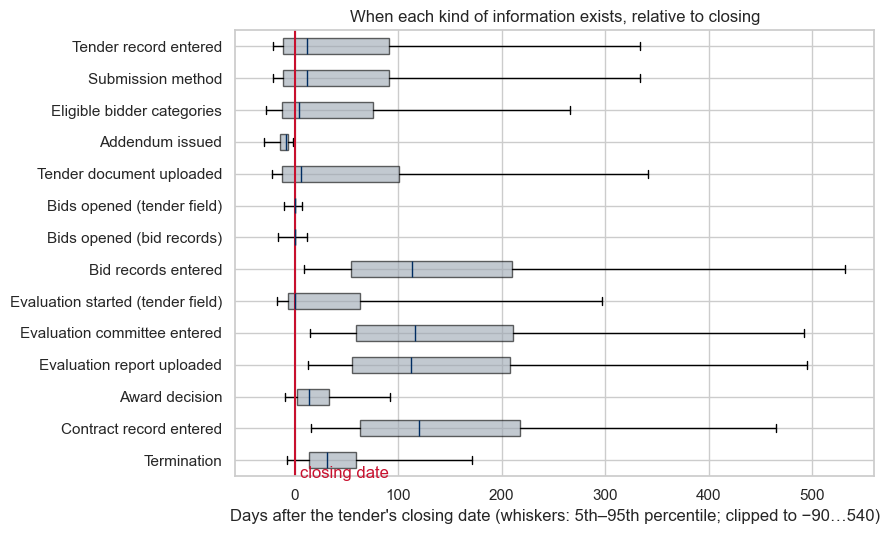

,date measures,dated records,median days after closing,% on or before closing,usable at the scoring point
information,,,,,
Tender record entered,record,202747,11.7,43.9,yes – its content
Submission method,record,203102,11.7,43.9,yes
Eligible bidder categories,record,5887,4.0,48.1,yes
Addendum issued,event,21429,-8.0,97.8,"yes, if dated before closing"
Tender document uploaded,record,220140,6.7,46.0,no – upload is retrospective
Bids opened (tender field),event,141973,0.0,87.8,no
Bids opened (bid records),event,349035,0.0,83.9,no
Bid records entered,record,421487,113.4,0.8,no
Evaluation started (tender field),event,186744,0.0,57.8,no


In [8]:
ten = db["tenders"][db["tenders"]["deleted_at"].isna() & db["tenders"]["published_at"].dt.year.between(*YEARS)]
ten = ten.set_index("id")
close_at = ten["close_at"]


def days_after_close(when, tender_id, date_only=False):
    """Days from the tender's closing date to `when` (positive = after closing)."""
    ref = close_at.reindex(tender_id.to_numpy())
    ref = ref.dt.normalize() if date_only else ref
    return (when.to_numpy() - ref.to_numpy()) / np.timedelta64(1, "D")


def alive(df):
    return df[df["deleted_at"].isna()] if "deleted_at" in df else df


docs = alive(db["documents"])
docs = docs[docs["documentable_type"] == "Tender"].assign(
    doc_type=lambda d: d["document_type_id"].map(db["document_types"].set_index("id")["description"]))
team = alive(db["tender_team_members"]).assign(
    team=lambda d: d["team_type_id"].map(db["team_types"].set_index("id")["name"]))
bids, awards, adds, terms = (alive(db[t]) for t in ["bidders", "contracts", "addenda", "tender_terminations"])
subm, cats = alive(db["submission_method_tender"]), alive(db["bidder_category_tender"])

SOURCES = [  # information, what the date measures, tender ids, dates, date-only column?, usable as a predictor?
    ("Tender record entered", "record", pd.Series(ten.index), ten["created_at"], False, "yes – its content"),
    ("Submission method", "record", subm["tender_id"], subm["created_at"], False, "yes"),
    ("Eligible bidder categories", "record", cats["tender_id"], cats["created_at"], False, "yes"),
    ("Addendum issued", "event", adds["tender_id"], adds["addendum_date"], True, "yes, if dated before closing"),
    ("Tender document uploaded", "record", docs.loc[docs["doc_type"] == "Tender Document", "documentable_id"],
     docs.loc[docs["doc_type"] == "Tender Document", "created_at"], False, "no – upload is retrospective"),
    ("Bids opened (tender field)", "event", pd.Series(ten.index), ten["opening_date"], True, "no"),
    ("Bids opened (bid records)", "event", bids["tender_id"], bids["opening_date"], True, "no"),
    ("Bid records entered", "record", bids["tender_id"], bids["created_at"], False, "no"),
    ("Evaluation started (tender field)", "event", pd.Series(ten.index), ten["evaluation_start_date"], False, "no"),
    ("Evaluation committee entered", "record", team.loc[team["team"].str.startswith("Eval"), "tender_id"],
     team.loc[team["team"].str.startswith("Eval"), "created_at"], False, "no"),
    ("Evaluation report uploaded", "record", docs.loc[docs["doc_type"] == "Evaluation Report", "documentable_id"],
     docs.loc[docs["doc_type"] == "Evaluation Report", "created_at"], False, "no"),
    ("Award decision", "event", awards["tender_id"], awards["award_date"], True, "no – this is the outcome"),
    ("Contract record entered", "record", awards["tender_id"], awards["created_at"], False, "no – this is the outcome"),
    ("Termination", "event", terms["tender_id"], terms["termination_date"], True, "no – this is the outcome"),
]
timing, lags = [], {}
for name, kind, ids, when, date_only, usable in SOURCES:
    d = days_after_close(when, ids, date_only)
    d = d[~np.isnan(d)]
    lags[name] = d
    timing.append({"information": name, "date measures": kind, "dated records": len(d),
                   "median days after closing": np.median(d), "% on or before closing": (d <= 0).mean() * 100,
                   "usable at the scoring point": usable})
timing = pd.DataFrame(timing).set_index("information").round(1)

fig, ax = plt.subplots(figsize=(9, 5.5))
names = list(lags)[::-1]
ax.boxplot([np.clip(lags[n], -90, 540) for n in names], vert=False, whis=(5, 95), showfliers=False,
           patch_artist=True, boxprops={"facecolor": GREY, "alpha": 0.6}, medianprops={"color": NAVY})
ax.set_yticks(range(1, len(names) + 1), names)
ax.axvline(0, color=RED, lw=1.5)
ax.text(5, 0.6, "closing date", color=RED, va="center")
ax.set(xlabel="Days after the tender's closing date (whiskers: 5th–95th percentile; clipped to −90…540)",
       title="When each kind of information exists, relative to closing")
savefig("du1_recording_timing")
timing

**Reading.** Three findings follow.
* **The portal is filled in retrospectively.** More than half of tender records are entered *after* their own
  closing date (median about 12 days after), and bids, evaluation committees, evaluation reports and contracts are
  entered a median of 110–120 days after closing (the contract figure mixes two recording regimes; see Section
  2.7). A record's entry date therefore says when someone reported it, not when it happened; only event dates can
  place information before or after the scoring point.
* **Admissible information.** The tender notice itself (method, category, dates, fee, validity, title), the
  submission method, the eligible bidder categories and addenda dated before closing (98% of addenda) are all
  determined by the closing date, and may be used as predictors even though they were often typed in later.
* **Inadmissible information.** Bid opening, evaluation, committee membership, award and termination all fall after
  closing. The tender table's own `opening_date`, `evaluation_start_date` and `evaluation_end_date` columns are
  post-closing events and are excluded with the bid and contract tables.

### 2.6 Recording coverage by year

The proposal asks whether missingness is systematically related to time or to the procuring entity. The plot below
shows, by publication year, the share of tenders with at least one recorded bid, contract and termination.

Tenders per year:
 year
2018.0    11867
2019.0    18721
2020.0    17518
2021.0    22867
2022.0    34487
2023.0    58155
2024.0    42645


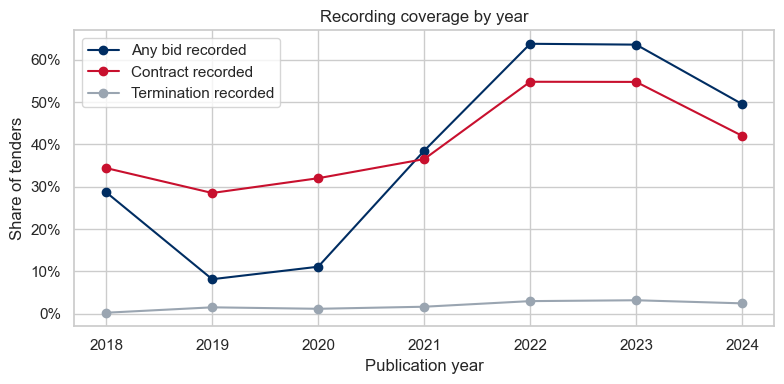

Awarded tenders with NO bid recorded: 9588


In [9]:
bidders = bidders[bidders["deleted_at"].isna()]
tenders["published_at"] = pd.to_datetime(tenders["published_at"], errors="coerce")
tenders["close_at"] = pd.to_datetime(tenders["close_at"], errors="coerce")
tenders["year"] = tenders["published_at"].dt.year

has_contract = tenders["id"].isin(contracts["tender_id"])
has_term = tenders["id"].isin(terminations["tender_id"])
has_bids = tenders["id"].isin(bidders["tender_id"])

coverage = pd.DataFrame({"year": tenders["year"], "Any bid recorded": has_bids,
                         "Contract recorded": has_contract, "Termination recorded": has_term})
coverage = coverage[coverage["year"].between(*YEARS)].groupby("year").mean()
print("Tenders per year:\n", tenders["year"].value_counts().sort_index().loc[YEARS[0]:YEARS[1]].to_string())

ax = coverage.plot(marker="o", color=[NAVY, RED, GREY], figsize=(8, 4))
ax.set(ylabel="Share of tenders", xlabel="Publication year", title="Recording coverage by year")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
savefig("01_recording_coverage")

print("Awarded tenders with NO bid recorded:", int((has_contract & ~has_bids).sum()))

**Reading.** Bid recording rises from under 10% of tenders in 2019 to over 60% in 2022–2023, and thousands of
awarded tenders have no bid recorded at all. A missing bid record therefore reflects *recording practice*, not the
absence of bids. This is the label-validity problem the proposal identifies, and it is why the outcome taxonomy in
Section 3 treats "no recorded activity" as undetermined rather than as failure.

### 2.7 Label maturity at the snapshot

Because contracts are entered months after closing (Section 2.5), a tender that closed shortly before the snapshot
may have been awarded without its contract having been entered yet.

Estimating how long entry takes needs care, because the contract entry timestamp is not recorded consistently: it
exists for contracts entered up to mid-2021 and from October 2023, and is empty for those entered in between
(first table below). Contracts of tenders closing in 2021–2023 that do carry a timestamp were entered as a backlog,
one to three years late. The current recording lag is therefore estimated from tenders that closed in **2023Q4**:
all their contracts are timestamped and every one of them was followed for at least 338 days (Panel B). Applying
that curve to each tender's actual follow-up time gives the expected completeness of the label by closing quarter.

Contract records with an entry timestamp, by the tender's closing year:
         contracts  with_entry_timestamp_pct
q                                          
2018.0       5191                      98.7
2019.0       6152                      96.2
2020.0       6921                      85.6
2021.0       9247                      19.0
2022.0      21410                      13.4
2023.0      37591                      62.7
2024.0      21535                     100.0 



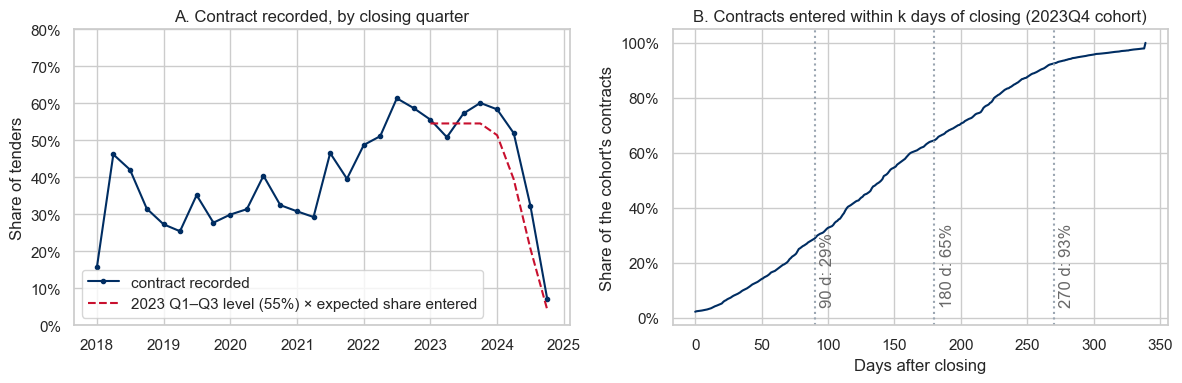

Cohort: 9,929 tenders closing in 2023Q4 with a recorded contract, followed ≥ 339 days


,tenders,contract_recorded_pct,expected_share_entered_pct
quarter,,,
2023Q1,15056,55.6,100.0
2023Q2,13521,50.8,100.0
2023Q3,12245,57.3,100.0
2023Q4,16565,60.1,100.0
2024Q1,14183,58.4,94.2
2024Q2,12885,51.9,72.3
2024Q3,9177,32.4,38.0
2024Q4,6692,7.2,7.8


In [10]:
first_entry = awards.groupby("tender_id")["created_at"].min()
dated = (awards.assign(q=awards["tender_id"].map(close_at).dt.year)
         .groupby("q")["created_at"].agg(contracts="size", with_entry_timestamp_pct=lambda s: s.notna().mean() * 100))
print("Contract records with an entry timestamp, by the tender's closing year:\n",
      dated.loc[YEARS[0]:YEARS[1]].round(1).to_string(), "\n")

cohort = ten.index[close_at.dt.to_period("Q") == pd.Period("2023Q4")]
cohort_lag = np.sort((first_entry.reindex(cohort) - close_at.reindex(cohort)).dt.days.dropna().to_numpy())
cohort_follow = (SNAPSHOT - close_at.reindex(cohort).max()).days


def share_entered(days):
    """Share of contracts entered within `days` of closing (2023Q4 cohort); 1 beyond the cohort's follow-up."""
    days = np.asarray(days, dtype=float)
    within = np.searchsorted(cohort_lag, days, side="right") / len(cohort_lag)
    return np.where(days >= cohort_follow, 1.0, within)


follow_up = (SNAPSHOT - close_at).dt.days
quarter = close_at.dt.to_period("Q")
by_quarter = pd.DataFrame({"awarded": ten.index.isin(awards["tender_id"]), "quarter": quarter,
                           "expected": share_entered(follow_up.clip(lower=0).fillna(0))}).groupby("quarter").agg(
    tenders=("awarded", "size"), contract_recorded_pct=("awarded", "mean"),
    expected_share_entered_pct=("expected", "mean")).loc[f"{YEARS[0]}Q1":f"{YEARS[1]}Q4"]
by_quarter[["contract_recorded_pct", "expected_share_entered_pct"]] *= 100
mature_rate = by_quarter.loc["2023Q1":"2023Q3", "contract_recorded_pct"].mean() / 100  # fully followed quarters

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
x = by_quarter.index.to_timestamp()
ax.plot(x, by_quarter["contract_recorded_pct"] / 100, marker="o", ms=3, color=NAVY, label="contract recorded")
recent = by_quarter.index >= pd.Period("2023Q1")
ax.plot(x[recent], by_quarter.loc[recent, "expected_share_entered_pct"] / 100 * mature_rate, ls="--", color=RED,
        label=f"2023 Q1–Q3 level ({mature_rate:.0%}) × expected share entered")
ax.set(title="A. Contract recorded, by closing quarter", ylabel="Share of tenders", ylim=(0, 0.8))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(loc="lower left")
ax = axes[1]
k = np.arange(0, cohort_follow + 1)
ax.plot(k, share_entered(k), color=NAVY)
for v in (90, 180, 270):
    ax.axvline(v, color=GREY, ls=":")
    ax.text(v + 4, 0.05, f"{v} d: {share_entered([v])[0]:.0%}", rotation=90, color="dimgray")
ax.set(title="B. Contracts entered within k days of closing (2023Q4 cohort)", xlabel="Days after closing",
       ylabel="Share of the cohort's contracts")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
savefig("du2_label_maturity")
print(f"Cohort: {len(cohort_lag):,} tenders closing in 2023Q4 with a recorded contract, followed ≥ {cohort_follow} days")
by_quarter.loc["2023Q1":].round(1)

**Reading.** The share of tenders with a recorded contract is steady at about 55–60% through 2023 and then falls,
to about a third in 2024Q3 and under a tenth in 2024Q4. Panel B accounts for the fall: under current practice only
about 30% of contracts are entered within 90 days of closing, two thirds within 180 days and about 95% within
300 days. Scaling the fully followed 2023 level by each quarter's expected share entered (dashed line)
reproduces the shape of the decline, but falls below the observed rates (about 21% expected against 32% observed in
2024Q3). The 2023Q4 cohort was partly entered during the 2024 catch-up, so it probably overstates today's lag and the
completeness estimates are conservative. Either way, for tenders
closing in 2024 a missing contract is therefore often *not yet entered* rather than a failure: their labels are
right-censored, and the 2024 test year would be scored against a systematically pessimistic outcome unless the
population is restricted to tenders followed long enough (Section 2.9).

### 2.8 Is missingness related to the procuring entity or to time?

For every tender column with between 1% and 99% missing values, the missingness indicator's variance is decomposed
by procuring entity and by publication year (η², the share of variance explained by the grouping). A tender fee of
zero is treated as missing.

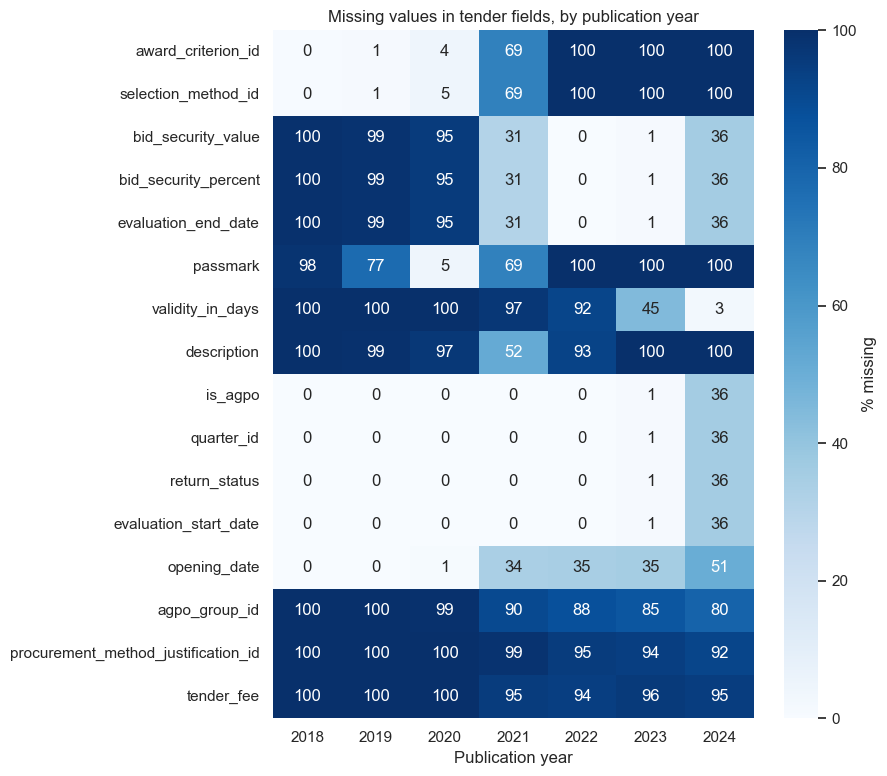

,missing_%,η² procuring entity,η² publication year,mainly explained by
award_criterion_id,73.545,0.209,0.853,year
selection_method_id,73.590,0.209,0.851,year
bid_security_value,34.330,0.165,0.640,year
bid_security_percent,34.330,0.165,0.640,year
evaluation_end_date,34.330,0.165,0.640,year
passmark,86.196,0.131,0.625,year
validity_in_days,62.653,0.170,0.614,year
description,93.058,0.078,0.342,year
is_agpo,7.920,0.100,0.281,year
quarter_id,7.920,0.100,0.281,year


In [11]:
def eta_squared(indicator, groups):
    overall = indicator.mean()
    g = indicator.groupby(groups)
    between = (g.size() * (g.mean() - overall) ** 2).sum()
    total = ((indicator - overall) ** 2).sum()
    return between / total


SKIP = {"updated_at", "updated_by", "deleted_at", "deleted_by"}
missing = ten.drop(columns=list(SKIP)).isna()
missing["tender_fee"] = ten["tender_fee"].fillna(0).eq(0)
missing = missing.loc[:, missing.mean().between(0.01, 0.99)]
year = ten["published_at"].dt.year
miss_struct = pd.DataFrame({
    "missing_%": missing.mean() * 100,
    "η² procuring entity": {c: eta_squared(missing[c].astype(float), ten["pe_id"]) for c in missing},
    "η² publication year": {c: eta_squared(missing[c].astype(float), year) for c in missing},
}).sort_values("η² publication year", ascending=False)
miss_struct["mainly explained by"] = np.where(miss_struct["η² publication year"] > miss_struct["η² procuring entity"],
                                              "year", "procuring entity")

fig, ax = plt.subplots(figsize=(9, 0.42 * len(missing.columns) + 1.2))
sns.heatmap(missing.groupby(year).mean().T.loc[miss_struct.index] * 100, annot=True, fmt=".0f", cmap="Blues",
            vmin=0, vmax=100, cbar_kws={"label": "% missing"}, ax=ax)
ax.set(xlabel="Publication year", ylabel="", title="Missing values in tender fields, by publication year")
savefig("du3_missingness_by_year")
miss_struct.round(3)

**Reading.** For most fields, missingness is explained far more by the year than by the procuring entity (η² up to
0.85 for year against at most 0.35 for entity). The heatmap shows why: the tender form changed over time. Award
criterion, selection method and pass mark were recorded in 2018–2020 and dropped from 2022; bid-security fields
and evaluation dates appear from 2021; validity period appears only in 2023–2024; and in 2024 a whole block of
fields (`is_agpo`, `quarter_id`, `return_status`, `evaluation_start_date`) is empty for 36% of tenders, which
suggests a new entry form for part of that year. A missing value in these fields is therefore a marker of *when* and
*through which form* a tender was entered, and a model would partly learn the calendar from it. The gap in
`is_agpo` also matters for the fairness audit: AGPO status is unknown for about a third of 2024 tenders. Missingness
tied to the entity, and so plausibly to administrative capacity as the literature suggests, appears mainly in
whether bid opening is recorded and whether a tender fee is charged.

### 2.9 Consequences for data preparation

| Finding | Consequence |
|---|---|
| The CSV extracts equal the dump (in East Africa Time) | Sections 3–8 read the extracts |
| 99.3% of tenders fall in 2018–2024; the snapshot is 4 Dec 2024 | Analysis window 2018–2024 |
| `status_id` is constant; bid-security fields are always zero or empty | Neither can serve as outcome or value measure |
| Records are entered retrospectively; bids, evaluation, committees and contracts post-date closing | Only tender-notice attributes and pre-closing addenda are predictors; entry dates are never used |
| Contracts are entered a median of about 4 months after closing; about 95% within 300 days | Labels for tenders closing in 2024 are right-censored: restrict the population by follow-up time, or report the 2024 test year as provisional |
| Missingness of several tender fields is driven by changes to the tender form; `is_agpo` is missing for 36% of 2024 tenders | The missingness indicators kept by the imputer (Section 4) partly encode the calendar; forward-chaining validation tests whether that generalises, and their attributions are read with this in mind (Section 6); the AGPO audit reports how many tenders lack the attribute |
| Submission method and eligible bidder categories exist for many tenders at closing | Candidate predictors (bidder categories overlap with AGPO status and must be treated like it) |

In [12]:
del db, docs, team, bids, awards, adds, terms, subm, cats  # free the dump tables; later sections use the extracts

## 3. Data Preparation
### 3.1 Analysis population

In [13]:
pe_info = (pe[["id", "pe_type_id", "county_id"]]
           .merge(pe_types[["id", "description"]].rename(columns={"id": "pe_type_id", "description": "pe_type"}), how="left")
           .merge(counties[["id", "name"]].rename(columns={"id": "county_id", "name": "county"}), how="left")
           .rename(columns={"id": "pe_id"}))
STRUCTURAL_NO_CONTRACT = ["Expression of Interest", "Prequalification", "Disposal of assets"]
method_name = methods.set_index("id")["title"]

flow = [("All tender records", len(tenders))]
pop = tenders[tenders["deleted_at"].isna()]
flow.append(("Not soft-deleted", len(pop)))
pop = pop[pop["year"].between(*YEARS)]
flow.append((f"Published {YEARS[0]}–{YEARS[1]}", len(pop)))
pop = pop[pop["published"] == 1]
flow.append(("Flagged as published on the portal", len(pop)))
pop = pop.assign(procurement_method=pop["procurement_method_id"].map(method_name))
pop = pop[~pop["procurement_method"].isin(STRUCTURAL_NO_CONTRACT)]
flow.append(("Excluding EOI, prequalification and disposal (no contract by design)", len(pop)))
pop = pop.merge(pe_info, on="pe_id", how="left").reset_index(drop=True)
if FAST:
    pop = pop.sample(frac=0.15, random_state=SEED).reset_index(drop=True)
    flow.append(("FAST subsample (15%)", len(pop)))
pd.DataFrame(flow, columns=["Step", "Tenders"])

,Step,Tenders
0,All tender records,207670
1,Not soft-deleted,204506
2,Published 2018–2024,203122
3,Flagged as published on the portal,192884
4,"Excluding EOI, prequalification and disposal (...",189980


### 3.2 Outcome taxonomy (Objective i)

Each tender is assigned to exactly one class, in priority order:

| Class | Rule | Interpretation |
|---|---|---|
| **Awarded** | a contract is recorded | award reached and published |
| **Terminated** | no contract; a termination is recorded | genuine, documented failure |
| **Undetermined** | no contract or termination; at least one bid recorded | bids received, outcome unknown (stalled or unpublished award) |
| **No recorded activity** | no contract, termination or bid recorded | non-response *or* non-publication: cannot be told apart |

In [14]:
CLASSES = ["Awarded", "Terminated", "Undetermined", "No recorded activity"]
c_ = pop["id"].isin(contracts["tender_id"])
t_ = pop["id"].isin(terminations["tender_id"])
b_ = pop["id"].isin(bidders["tender_id"])
pop["outcome_class"] = np.select([c_, t_, b_], CLASSES[:3], CLASSES[3])

tax = pop["outcome_class"].value_counts().reindex(CLASSES).to_frame("tenders")
tax["share_%"] = (tax["tenders"] / len(pop) * 100).round(1)
tax

,tenders,share_%
outcome_class,,
Awarded,92013,48.4
Terminated,4723,2.5
Undetermined,11791,6.2
No recorded activity,81453,42.9


**Validating the taxonomy.** Four checks test whether the classes mean what they claim:
1. *Flag agreement*: the tender-level `terminated` flag should agree with the termination table.
2. *Overlap*: tenders with both a contract and a termination should be rare.
3. *Termination reasons*: the recorded reasons should describe genuine failure.
4. *Clustering by procuring entity*: if "no recorded activity" were genuine non-response it should vary mainly with
   tender characteristics; if it is a reporting artefact it should cluster by procuring entity. We compare the share
   of variance explained by the procuring entity (η²) for each class indicator.

In [15]:
print("1. Flag agreement (terminated flag vs termination table):",
      f"{(pop['terminated'].eq(1) == t_).mean():.4%}")
print("2. Tenders with both a contract and a termination:", int((c_ & t_).sum()))

reasons = (terminations.merge(term_reasons[["id", "description"]], left_on="termination_reason_id", right_on="id")
           .query("tender_id in @pop.id")["description"].str.strip().str.rstrip(";").str.capitalize()
           .value_counts(normalize=True).head(8).mul(100).round(1))
print("\n3. Most common termination reasons (% of terminations):\n", reasons.to_string())


eta = pd.DataFrame({cls: {"procuring entity": eta_squared(pop["outcome_class"].eq(cls).astype(float), pop["pe_id"]),
                          "procurement method": eta_squared(pop["outcome_class"].eq(cls).astype(float), pop["procurement_method"])}
                    for cls in CLASSES}).T.round(3)
print("\n4. Share of variance in each class indicator explained by grouping (eta squared):")
eta

1. Flag agreement (terminated flag vs termination table): 99.9989%
2. Tenders with both a contract and a termination: 19

3. Most common termination reasons (% of terminations):
 description
All evaluated tenders are non-responsive         43.7
Inadequate budgetary provision                   20.9
Material governance issues have been detected    10.7
Operation of law                                  8.1
No tender was received                            6.3
Prices of the bids are above market prices        3.4
Substantial technological change.                 2.0
Force majeure                                     1.8

4. Share of variance in each class indicator explained by grouping (eta squared):


,procuring entity,procurement method
Awarded,0.231,0.127
Terminated,0.078,0.011
Undetermined,0.046,0.005
No recorded activity,0.260,0.125


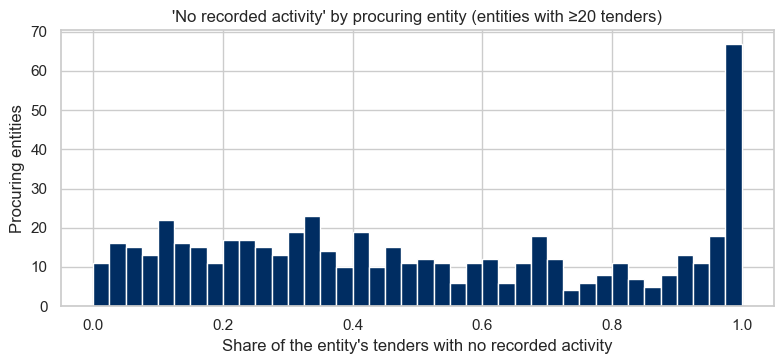

Entities with ≥90% of tenders showing no recorded activity: 19.5% of 559


In [16]:
pe_share = pop.groupby("pe_id")["outcome_class"].apply(lambda s: s.eq("No recorded activity").mean())
pe_n = pop.groupby("pe_id").size()
pe_share = pe_share[pe_n >= 20]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(pe_share, bins=40, color=NAVY)
ax.set(xlabel="Share of the entity's tenders with no recorded activity", ylabel="Procuring entities",
       title="'No recorded activity' by procuring entity (entities with ≥20 tenders)")
savefig("02_no_activity_by_pe")
print(f"Entities with ≥90% of tenders showing no recorded activity: {(pe_share >= 0.9).mean():.1%} of {len(pe_share)}")

### 3.3 Alternative outcome definitions

The proposal commits to estimating models under alternative outcome definitions and reporting the sensitivity of
the conclusions. Three definitions are compared; in all of them **y = 1 means the tender reached contract award**.

| Definition | Positive (y = 1) | Negative (y = 0) | Excluded |
|---|---|---|---|
| **D1 Naive** | Awarded | everything else | – |
| **D2 Observed activity** (primary, pre-specified) | Awarded | Terminated + Undetermined | No recorded activity |
| **D3 Strict failure** | Awarded | Terminated | Undetermined, No recorded activity |

D1 reproduces the label of the earlier notebook. D2 is primary because it removes records whose status is
unknowable while keeping enough negatives to model. D3 isolates documented failure only.

In [17]:
DEFS = {
    "D1": {"name": "D1 Naive", "neg": ["Terminated", "Undetermined", "No recorded activity"]},
    "D2": {"name": "D2 Observed activity", "neg": ["Terminated", "Undetermined"]},
    "D3": {"name": "D3 Strict failure", "neg": ["Terminated"]},
}


def label(df, d):
    keep = df["outcome_class"].isin(["Awarded"] + DEFS[d]["neg"])
    return keep, (df["outcome_class"] == "Awarded").astype(int)


rows = []
for d in DEFS:
    keep, y = label(pop, d)
    rows.append({"definition": DEFS[d]["name"], "tenders": int(keep.sum()), "awarded": int(y[keep].sum()),
                 "not awarded": int((1 - y[keep]).sum()), "award rate": f"{y[keep].mean():.1%}"})
pd.DataFrame(rows)

,definition,tenders,awarded,not awarded,award rate
0,D1 Naive,189980,92013,97967,48.4%
1,D2 Observed activity,108527,92013,16514,84.8%
2,D3 Strict failure,96736,92013,4723,95.1%


### 3.4 Feature engineering (information available by the closing date)

| Group | Features |
|---|---|
| Timing | days from publication to closing; publication month; fiscal quarter (July–June year); days to fiscal-year end |
| Tender design | procurement method; procurement category; tender validity period; tender fee (indicator and log amount) |
| Changes before closing | number of addenda issued before the original closing date; closing date extended |
| Procuring entity | entity type; county; entity's number of previously published tenders (experience/size) |
| Text | TF-IDF of the tender title reduced to 50 dimensions (truncated SVD); description present |

**Where the data forced a change from the proposal:**
* *Tender value*: no pre-award value exists in the export (bid-security values and percentages are always zero, and
  contract amounts exist only after award), so value-based features are omitted.
* *Competition measures*: bid records are opened at or after closing and are inconsistently recorded (Section 2.2),
  and evaluation scores are empty, so bidder counts and score dispersion are not used as predictors.
* *Protected attributes*: AGPO status (and the almost identical reservation flag) is **not** a predictor; it is held
  out for the fairness audit. County is both a predictor and an audited attribute, as in the proposal.

In [18]:
def fiscal_quarter(month):
    return ((month - 7) % 12) // 3 + 1


feat = pop.copy()
feat["days_to_close"] = (feat["close_at"] - feat["published_at"]).dt.days
feat.loc[~feat["days_to_close"].between(0, 180), "days_to_close"] = np.nan
feat["validity_days"] = feat["validity_in_days"].where(feat["validity_in_days"].between(1, 730))
feat["has_tender_fee"] = (feat["tender_fee"].fillna(0) > 0).astype(int)
feat["log_tender_fee"] = np.log1p(feat["tender_fee"].clip(lower=0).fillna(0))
feat["pub_month"] = feat["published_at"].dt.month.astype(str)
feat["fiscal_quarter"] = "Q" + fiscal_quarter(feat["published_at"].dt.month).astype(str)
fy_end = pd.to_datetime((feat["published_at"].dt.year + (feat["published_at"].dt.month >= 7)).astype(str) + "-06-30")
feat["days_to_fy_end"] = (fy_end - feat["published_at"]).dt.days

ad = addenda[addenda["deleted_at"].isna()].merge(tenders[["id", "close_at"]], left_on="tender_id", right_on="id")
ad["addendum_date"] = pd.to_datetime(ad["addendum_date"], errors="coerce")
ad = ad[ad["addendum_date"] <= ad["close_at"]]
ad["extends"] = ad["new_closing_date"].notna() | ad["extending_date"].notna()
ad_agg = ad.groupby("tender_id").agg(n_addenda_pre_close=("id_x", "size"), closing_extended=("extends", "max"))
feat = feat.merge(ad_agg, left_on="id", right_index=True, how="left")
feat["n_addenda_pre_close"] = feat["n_addenda_pre_close"].fillna(0)
feat["closing_extended"] = feat["closing_extended"].fillna(False).astype(int)

# entity experience: number of tenders the entity published earlier (label-free, uses the past only)
allpub = tenders.loc[tenders["deleted_at"].isna(), ["id", "pe_id", "published_at"]].sort_values(["published_at", "id"])
allpub["pe_prior_tenders"] = allpub.groupby("pe_id").cumcount()
feat = feat.merge(allpub[["id", "pe_prior_tenders"]], on="id", how="left")
feat["log_pe_prior_tenders"] = np.log1p(feat["pe_prior_tenders"])

feat["title"] = feat["title"].fillna("").astype(str)
feat["title_words"] = feat["title"].str.split().str.len()
feat["has_description"] = feat["description"].notna().astype(int)
feat["procurement_category"] = feat["procurement_category_id"].map(categories.set_index("id")["title"])

NUM = ["days_to_close", "validity_days", "has_tender_fee", "log_tender_fee", "days_to_fy_end",
       "n_addenda_pre_close", "closing_extended", "log_pe_prior_tenders", "title_words", "has_description"]
CAT = ["procurement_method", "procurement_category", "pe_type", "county", "pub_month", "fiscal_quarter"]
TEXT = "title"
for c in CAT + ["pe_type"]:
    feat[c] = feat[c].fillna("Unknown").astype(object)
feat["agpo"] = feat["is_agpo"].map({1.0: "AGPO", 0.0: "Non-AGPO"}).fillna("Unknown")

print("Feature frame:", feat.shape)
feat[NUM].describe().T.round(2)

Feature frame: (189980, 63)


,count,mean,std,min,25%,50%,75%,max
days_to_close,187725.0,11.57,11.80,0.0,6.00,9.0,15.00,180.00
validity_days,69485.0,111.10,69.31,1.0,90.00,120.0,140.00,730.00
has_tender_fee,189980.0,0.04,0.19,0.0,0.00,0.0,0.00,1.00
log_tender_fee,189980.0,0.29,1.55,0.0,0.00,0.0,0.00,20.62
days_to_fy_end,189980.0,181.38,100.11,0.0,99.00,177.0,264.00,365.00
n_addenda_pre_close,189980.0,0.11,0.52,0.0,0.00,0.0,0.00,60.00
closing_extended,189980.0,0.07,0.25,0.0,0.00,0.0,0.00,1.00
log_pe_prior_tenders,189980.0,5.80,1.69,0.0,4.76,5.9,6.94,9.63
title_words,189980.0,9.15,5.06,0.0,6.00,8.0,11.00,109.00
has_description,189980.0,0.07,0.25,0.0,0.00,0.0,0.00,1.00


### 3.5 Data exploration
Award rates (primary definition D2) by tender characteristics, outcome-class shares by year, and univariate
association of each candidate predictor with the outcome.

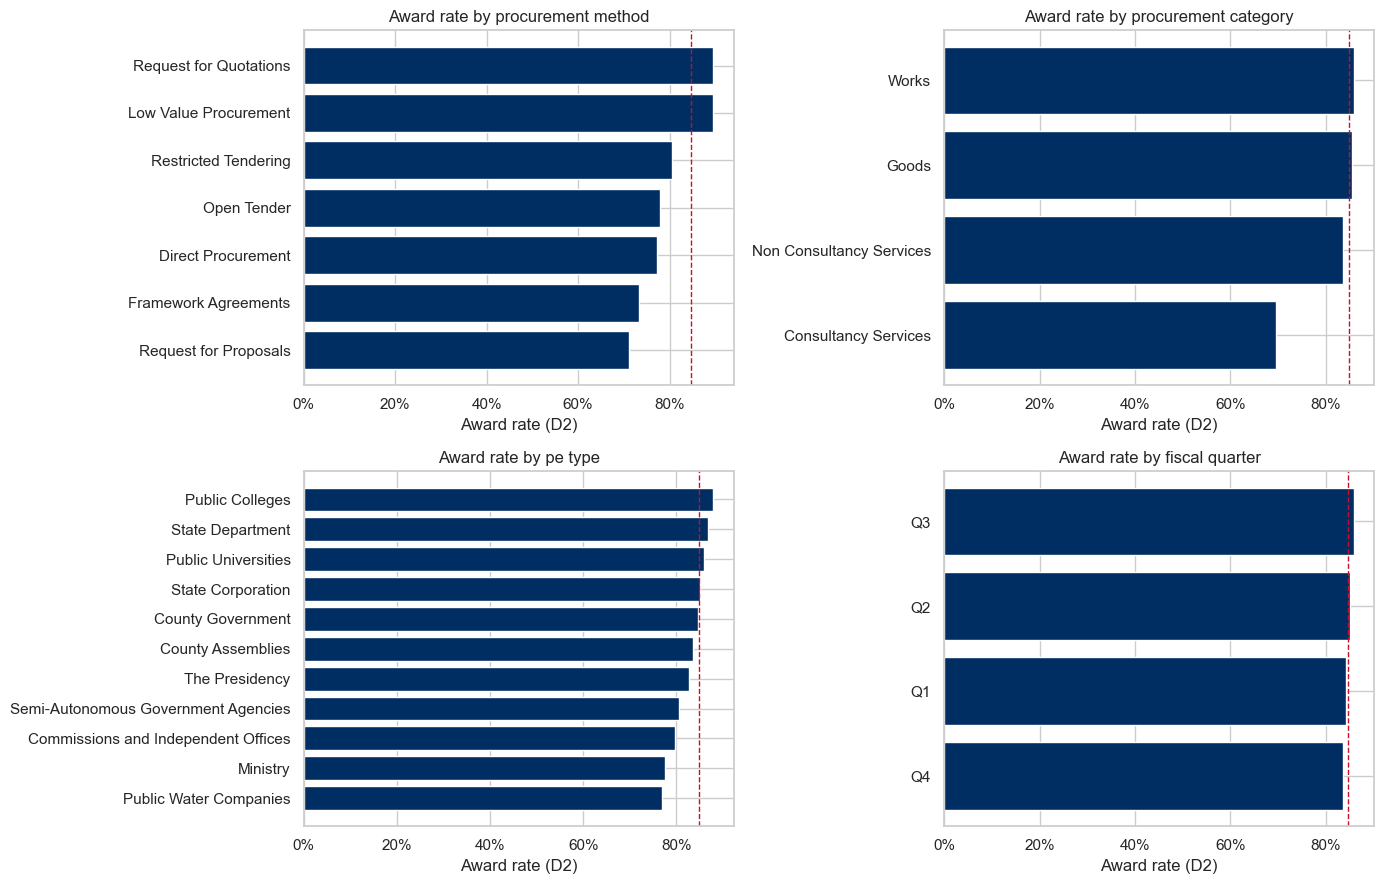

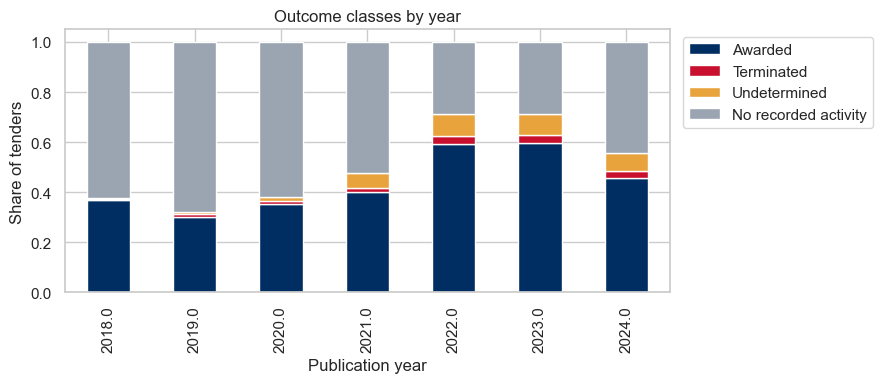

In [19]:
keep2, y2 = label(feat, PRIMARY_DEF)
eda = feat[keep2].assign(y=y2[keep2])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, ["procurement_method", "procurement_category", "pe_type", "fiscal_quarter"]):
    s = eda.groupby(col)["y"].agg(["mean", "size"])
    s = s[s["size"] >= 200].sort_values("mean")
    ax.barh(s.index.astype(str), s["mean"], color=NAVY)
    ax.axvline(eda["y"].mean(), color=RED, ls="--", lw=1)
    ax.set(title=f"Award rate by {col.replace('_', ' ')}", xlabel="Award rate (D2)")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
savefig("03_award_rate_by_category")

shares = pd.crosstab(feat["year"], feat["outcome_class"], normalize="index")[CLASSES]
ax = shares.plot(kind="bar", stacked=True, color=[NAVY, RED, "#E8A33D", GREY], figsize=(9, 4))
ax.set(ylabel="Share of tenders", xlabel="Publication year", title="Outcome classes by year")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("04_outcome_classes_by_year")

In [20]:
def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    chi2_stat = chi2_contingency(tab, correction=False)[0]
    return np.sqrt(chi2_stat / (tab.values.sum() * (min(tab.shape) - 1)))


assoc = []
for c in CAT:
    assoc.append({"feature": c, "type": "categorical", "association": cramers_v(eda[c], eda["y"]), "measure": "Cramér's V"})
for c in NUM:
    v = eda[[c, "y"]].dropna()
    auc = roc_auc_score(v["y"], v[c]) if v[c].nunique() > 1 else 0.5
    assoc.append({"feature": c, "type": "numeric", "association": abs(auc - 0.5) * 2, "measure": "|2·AUC − 1|"})
pd.DataFrame(assoc).sort_values("association", ascending=False).round(3)

,feature,type,association,measure
6,days_to_close,numeric,0.194,|2·AUC − 1|
7,validity_days,numeric,0.184,|2·AUC − 1|
0,procurement_method,categorical,0.166,Cramér's V
14,title_words,numeric,0.127,|2·AUC − 1|
3,county,categorical,0.095,Cramér's V
1,procurement_category,categorical,0.076,Cramér's V
11,n_addenda_pre_close,numeric,0.063,|2·AUC − 1|
12,closing_extended,numeric,0.063,|2·AUC − 1|
2,pe_type,categorical,0.052,Cramér's V
8,has_tender_fee,numeric,0.031,|2·AUC − 1|


**County-level patterns.** The first map shows the D2 award rate by the procuring entity's county; the second shows
the share of tenders with no recorded activity, which the taxonomy treats as a reporting signal.
(National entities are registered mostly under Nairobi.)

In [21]:
try:
    import geopandas as gpd
    geo = gpd.read_file("ke.json")
    norm_name = lambda s: s.str.lower().str.replace(r"[^a-z]", "", regex=True)
    geo["key"] = norm_name(geo["name"])
    by_county = pd.DataFrame({
        "award_rate_D2": eda.groupby("county")["y"].mean(),
        "no_activity_share": feat.groupby("county")["outcome_class"].apply(lambda s: s.eq("No recorded activity").mean()),
    }).reset_index()
    by_county["key"] = norm_name(by_county["county"])
    g = geo.merge(by_county, on="key", how="left")
    print("Counties matched to the map:", int(g["award_rate_D2"].notna().sum()), "of", len(g))
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    for ax, col, cmap, ttl in zip(axes, ["award_rate_D2", "no_activity_share"], ["Blues", "Reds"],
                                  ["Award rate (D2)", "Share with no recorded activity"]):
        g.plot(column=col, cmap=cmap, legend=True, ax=ax, edgecolor="white", linewidth=0.4,
               missing_kwds={"color": "lightgrey"})
        ax.set_title(ttl); ax.axis("off")
    savefig("05_county_maps")
except Exception as e:  # mapping is illustrative only
    print("County map skipped:", e)

County map skipped: No module named 'geopandas'


## 4. Modelling (Objective ii)
### 4.1 Preprocessing, fitted inside every training window

All preprocessing is learned from the training window only and then applied to the test year, so no information
from the future leaks into training. Missing numeric values are imputed with the median **within the procuring-entity
type stratum** (falling back to the overall median), with missingness indicators retained, as the proposal specifies.

In [22]:
class GroupMedianImputer(BaseEstimator, TransformerMixin):
    """Median imputation within a grouping column, with missingness indicators."""

    def __init__(self, group_col="pe_type"):
        self.group_col = group_col

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.num_cols_ = [c for c in X.columns if c != self.group_col]
        self.global_ = X[self.num_cols_].median()
        self.group_ = X.groupby(self.group_col)[self.num_cols_].median()
        self.ind_cols_ = [c for c in self.num_cols_ if X[c].isna().any()]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        out = X[self.num_cols_].astype(float)
        ind = out[self.ind_cols_].isna().astype(float).add_suffix("_missing")
        grp = self.group_.reindex(X[self.group_col].values)
        grp.index = X.index
        out = out.fillna(grp).fillna(self.global_)
        return pd.concat([out, ind], axis=1).to_numpy(dtype=float)

    def get_feature_names_out(self, input_features=None):
        return np.array(self.num_cols_ + [f"{c}_missing" for c in self.ind_cols_])


def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", GroupMedianImputer("pe_type")), ("scale", StandardScaler())]), NUM + ["pe_type"]),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), CAT),
        ("txt", Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=20000,
                                                    sublinear_tf=True, stop_words="english")),
                          ("svd", TruncatedSVD(n_components=50, random_state=SEED))]), TEXT),
    ], sparse_threshold=0)


X_COLS = NUM + CAT + [TEXT]

### 4.2 Model families and hyperparameter tuning

Five model families are trained, as in the proposal: logistic regression, random forest, gradient boosting
(scikit-learn's histogram-based implementation of Friedman's algorithm), XGBoost, and a stacked ensemble whose
logistic meta-learner is trained on out-of-fold predictions of the four base models.

Hyperparameters are tuned once, by randomised search scored on ROC-AUC, fitting on 2018–2019 and validating on 2020.
Because 2020 precedes every test year, tuning never sees test data. The same split fixes each model's classification
threshold (the value that maximises macro-F1 on 2020), so thresholds are also chosen without test data.

In [23]:
BASE_MODELS = {
    "Logistic regression": (LogisticRegression(max_iter=3000),
                            {"C": np.logspace(-3, 1, 20)}),
    "Random forest": (RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
                      {"max_depth": [12, 18, 24, None], "min_samples_leaf": [1, 3, 5, 10],
                       "max_features": ["sqrt", 0.3]}),
    "Gradient boosting": (HistGradientBoostingClassifier(max_iter=400, random_state=SEED),
                          {"learning_rate": [0.03, 0.05, 0.1], "max_leaf_nodes": [31, 63, 127],
                           "l2_regularization": [0.0, 0.1, 1.0], "min_samples_leaf": [20, 50, 100]}),
    "XGBoost": (xgb.XGBClassifier(n_estimators=400, tree_method="hist", n_jobs=-1, random_state=SEED,
                                  eval_metric="logloss"),
                {"max_depth": [4, 6, 8], "learning_rate": [0.03, 0.05, 0.1], "subsample": [0.7, 0.85, 1.0],
                 "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 5, 10], "reg_lambda": [1, 5]}),
}
MODEL_NAMES = list(BASE_MODELS) + ["Stacked ensemble"]


def build_models(params):
    models = {n: clone(est).set_params(**params[n]) for n, (est, _) in BASE_MODELS.items()}
    models["Stacked ensemble"] = StackingClassifier(
        estimators=[(n.split()[0].lower(), clone(m)) for n, m in models.items()],
        final_estimator=LogisticRegression(max_iter=2000),
        cv=StratifiedKFold(5, shuffle=True, random_state=SEED), stack_method="predict_proba", n_jobs=1)
    return models


def best_threshold(y, p):
    grid = np.linspace(0.05, 0.95, 91)
    scores = [f1_score(y, (p >= t).astype(int), average="macro") for t in grid]
    return float(grid[int(np.argmax(scores))])


t0 = time.time()
keep, y_all = label(feat, PRIMARY_DEF)
tune = feat[keep & feat["year"].isin(TUNE_TRAIN_YEARS + [TUNE_VAL_YEAR])]
y_tune = y_all[tune.index]
is_val = (tune["year"] == TUNE_VAL_YEAR).to_numpy()
pre = make_preprocessor().fit(tune.loc[~is_val, X_COLS])
X_tune = pre.transform(tune[X_COLS])
split = PredefinedSplit(np.where(is_val, 0, -1))

BEST_PARAMS, tuning_rows = {}, []
for name, (est, space) in BASE_MODELS.items():
    search = RandomizedSearchCV(est, space, n_iter=min(N_ITER, np.prod([len(v) for v in space.values()])),
                                scoring="roc_auc", cv=split, random_state=SEED, refit=False, n_jobs=1)
    search.fit(X_tune, y_tune)
    BEST_PARAMS[name] = search.best_params_
    tuning_rows.append({"model": name, "validation ROC-AUC (2020)": round(search.best_score_, 4),
                        "best parameters": search.best_params_})
print(f"Tuning finished in {(time.time() - t0) / 60:.1f} min")
pd.DataFrame(tuning_rows)

  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.

Tuning finished in 1.3 min


,model,validation ROC-AUC (2020),best parameters
0,Logistic regression,0.7121,{'C': 0.04832930238571752}
1,Random forest,0.7010,"{'min_samples_leaf': 1, 'max_features': 'sqrt'..."
2,Gradient boosting,0.7357,"{'min_samples_leaf': 50, 'max_leaf_nodes': 63,..."
3,XGBoost,0.7224,"{'subsample': 0.85, 'reg_lambda': 5, 'min_chil..."


In [24]:
# classification thresholds per model and definition, chosen on the 2020 validation year
THRESHOLDS = {}
for d in DEFS:
    keep_d, y_d = label(feat, d)
    tr = feat[keep_d & feat["year"].isin(TUNE_TRAIN_YEARS)]
    va = feat[keep_d & (feat["year"] == TUNE_VAL_YEAR)]
    pre_d = make_preprocessor().fit(tr[X_COLS])
    Xtr, Xva = pre_d.transform(tr[X_COLS]), pre_d.transform(va[X_COLS])
    for name, m in build_models(BEST_PARAMS).items():
        m.fit(Xtr, y_d[tr.index])
        THRESHOLDS[(d, name)] = best_threshold(y_d[va.index], m.predict_proba(Xva)[:, 1])
pd.Series(THRESHOLDS).unstack().round(2)

,Gradient boosting,Logistic regression,Random forest,Stacked ensemble,XGBoost
D1,0.38,0.33,0.34,0.31,0.33
D2,0.94,0.86,0.88,0.94,0.95
D3,0.88,0.90,0.68,0.91,0.88


### 4.3 Forward-chaining temporal validation

For each test year *Y* in 2021–2024, the models are trained on all tenders published from 2018 to *Y* − 1 and
evaluated on tenders published in *Y*. This is repeated for each outcome definition.

In [25]:
t0 = time.time()
pred_rows = []
for d in DEFS:
    keep_d, y_d = label(feat, d)
    for Y in TEST_YEARS:
        tr = feat[keep_d & feat["year"].between(YEARS[0], Y - 1)]
        te = feat[keep_d & (feat["year"] == Y)]
        pre_f = make_preprocessor().fit(tr[X_COLS])
        Xtr, Xte = pre_f.transform(tr[X_COLS]), pre_f.transform(te[X_COLS])
        for name, m in build_models(BEST_PARAMS).items():
            m.fit(Xtr, y_d[tr.index])
            pred_rows.append(pd.DataFrame({"definition": d, "test_year": Y, "model": name, "id": te["id"].values,
                                           "y": y_d[te.index].values, "p": m.predict_proba(Xte)[:, 1]}))
        print(f"{d} | test {Y} | train n={len(tr):,} | test n={len(te):,} | {(time.time() - t0) / 60:.1f} min")
preds = pd.concat(pred_rows, ignore_index=True)
preds["thr"] = [THRESHOLDS[(d, m)] for d, m in zip(preds["definition"], preds["model"])]
preds["yhat"] = (preds["p"] >= preds["thr"]).astype(int)
preds.to_csv(OUT_DIR / "out_of_time_predictions.csv", index=False)
print(f"Forward-chaining finished in {(time.time() - t0) / 60:.1f} min")

D1 | test 2021 | train n=44,565 | test n=20,924 | 2.0 min


D1 | test 2022 | train n=65,489 | test n=31,855 | 4.7 min


D1 | test 2023 | train n=97,344 | test n=53,501 | 8.4 min


D1 | test 2024 | train n=150,845 | test n=39,135 | 13.8 min


D2 | test 2021 | train n=15,864 | test n=9,992 | 14.5 min


D2 | test 2022 | train n=25,856 | test n=22,683 | 15.7 min


... (3 outputs left out)

D3 | test 2022 | train n=24,213 | test n=19,901 | 22.6 min


D3 | test 2023 | train n=44,114 | test n=33,663 | 24.1 min


D3 | test 2024 | train n=77,777 | test n=18,959 | 26.8 min


Forward-chaining finished in 27.0 min


## 5. Evaluation (Objective ii)
### 5.1 Performance under temporal validation
Metrics follow the proposal: accuracy, precision, recall and F₁ for the award class, and ROC-AUC. F₁ for the
non-award class and balanced accuracy are added because, under D2 and D3, non-award is the minority class of interest.

In [26]:
def metrics(y, p, yhat):
    return {"Accuracy": accuracy_score(y, yhat), "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat), "F1 (award)": f1_score(y, yhat),
            "F1 (non-award)": f1_score(1 - y, 1 - yhat), "Balanced acc.": balanced_accuracy_score(y, yhat),
            "ROC-AUC": roc_auc_score(y, p)}


per_year = (preds.groupby(["definition", "model", "test_year"])
            .apply(lambda g: pd.Series(metrics(g["y"], g["p"], g["yhat"]))).reset_index())
pooled = (preds.groupby(["definition", "model"])
          .apply(lambda g: pd.Series(metrics(g["y"], g["p"], g["yhat"]))).reset_index())
pooled.to_csv(OUT_DIR / "metrics_pooled.csv", index=False)
per_year.to_csv(OUT_DIR / "metrics_by_year.csv", index=False)
pooled[pooled["definition"] == PRIMARY_DEF].drop(columns="definition").set_index("model").round(4)

,Accuracy,Precision,Recall,F1 (award),F1 (non-award),Balanced acc.,ROC-AUC
model,,,,,,,
Gradient boosting,0.3665,0.8920,0.2706,0.4152,0.3090,0.5546,0.6252
Logistic regression,0.6062,0.8676,0.6209,0.7238,0.3139,0.5772,0.6067
Random forest,0.5351,0.8794,0.5107,0.6461,0.3226,0.5831,0.6221
Stacked ensemble,0.3403,0.8887,0.2358,0.3727,0.3044,0.5452,0.6250
XGBoost,0.3389,0.8884,0.2340,0.3704,0.3041,0.5447,0.6202


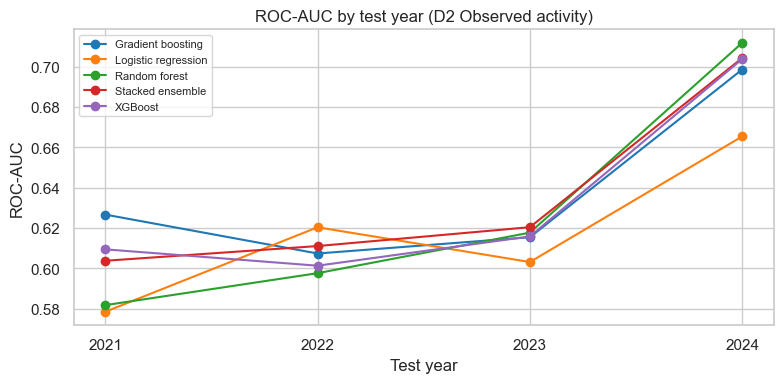

test_year,2021,2022,2023,2024
model,,,,
Gradient boosting,0.6266,0.6074,0.6154,0.6985
Logistic regression,0.5785,0.6204,0.6031,0.6654
Random forest,0.5818,0.5976,0.6177,0.7117
Stacked ensemble,0.6038,0.6110,0.6204,0.7042
XGBoost,0.6094,0.6013,0.6158,0.7037


In [27]:
auc_year = per_year[per_year["definition"] == PRIMARY_DEF].pivot(index="model", columns="test_year", values="ROC-AUC")
fig, ax = plt.subplots(figsize=(8, 4))
for i, (m, row) in enumerate(auc_year.iterrows()):
    ax.plot(row.index, row.values, marker="o", label=m, color=sns.color_palette("tab10")[i])
ax.set(xlabel="Test year", ylabel="ROC-AUC", title=f"ROC-AUC by test year ({DEFS[PRIMARY_DEF]['name']})",
       xticks=TEST_YEARS)
ax.legend(fontsize=8)
savefig("06_auc_by_year")
auc_year.round(4)

### 5.2 Bootstrap confidence intervals
95% percentile intervals from resampling the pooled out-of-time predictions (primary definition).

In [28]:
rng = np.random.default_rng(SEED)
ci_rows = []
P = preds[preds["definition"] == PRIMARY_DEF]
n = P.groupby("model").size().iloc[0]
idx = rng.integers(0, n, size=(N_BOOT, n))
for name, g in P.groupby("model", sort=False):
    y, p, yh = g["y"].to_numpy(), g["p"].to_numpy(), g["yhat"].to_numpy()
    boot = np.array([[roc_auc_score(y[i], p[i]), f1_score(1 - y[i], 1 - yh[i]), accuracy_score(y[i], yh[i])] for i in idx])
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    point = [roc_auc_score(y, p), f1_score(1 - y, 1 - yh), accuracy_score(y, yh)]
    ci_rows.append({"model": name, **{f"{k}": f"{v:.3f} [{a:.3f}, {b:.3f}]"
                                       for k, v, a, b in zip(["ROC-AUC", "F1 (non-award)", "Accuracy"], point, lo, hi)}})
pd.DataFrame(ci_rows).set_index("model")

,ROC-AUC,F1 (non-award),Accuracy
model,,,
Logistic regression,"0.607 [0.602, 0.612]","0.314 [0.309, 0.319]","0.606 [0.603, 0.609]"
Random forest,"0.622 [0.617, 0.627]","0.323 [0.318, 0.327]","0.535 [0.532, 0.538]"
Gradient boosting,"0.625 [0.620, 0.630]","0.309 [0.305, 0.313]","0.367 [0.364, 0.370]"
XGBoost,"0.620 [0.615, 0.625]","0.304 [0.300, 0.308]","0.339 [0.336, 0.342]"
Stacked ensemble,"0.625 [0.620, 0.630]","0.304 [0.300, 0.308]","0.340 [0.337, 0.344]"


### 5.3 Significance testing between models
Differences in ROC-AUC are tested with DeLong's test for correlated ROC curves (fast algorithm of Sun & Xu, 2014),
and paired differences in classification with McNemar's test, each comparing the best model with every other model.

In [29]:
def delong(y, p1, p2):
    y = np.asarray(y).astype(bool)
    m, n_ = y.sum(), (~y).sum()
    aucs, v10, v01 = [], [], []
    for p in (np.asarray(p1), np.asarray(p2)):
        x, z = p[y], p[~y]
        tx, tz, tall = rankdata(x), rankdata(z), rankdata(np.concatenate([x, z]))
        aucs.append((tall[:m].sum() - m * (m + 1) / 2) / (m * n_))
        v10.append((tall[:m] - tx) / n_)
        v01.append(1 - (tall[m:] - tz) / m)
    S = np.cov(np.vstack(v10)) / m + np.cov(np.vstack(v01)) / n_
    diff = aucs[0] - aucs[1]
    z = diff / np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1])
    return diff, z, 2 * norm.sf(abs(z))


wide = P.pivot(index="id", columns="model", values="p")
wide_hat = P.pivot(index="id", columns="model", values="yhat")
y_w = P.drop_duplicates("id").set_index("id")["y"].reindex(wide.index)
best = pooled[pooled["definition"] == PRIMARY_DEF].sort_values("ROC-AUC", ascending=False)["model"].iloc[0]
tests = []
for other in MODEL_NAMES:
    if other == best:
        continue
    diff, z, p_dl = delong(y_w, wide[best], wide[other])
    correct_b, correct_o = wide_hat[best] == y_w, wide_hat[other] == y_w
    table = pd.crosstab(correct_b, correct_o).reindex(index=[True, False], columns=[True, False], fill_value=0)
    mc = mcnemar(table.values, exact=False, correction=True)
    tests.append({"comparison": f"{best} vs {other}", "AUC difference": round(diff, 4), "DeLong z": round(z, 2),
                  "DeLong p": f"{p_dl:.2e}", "McNemar χ²": round(mc.statistic, 1), "McNemar p": f"{mc.pvalue:.2e}"})
print("Selected model (highest pooled ROC-AUC):", best)
pd.DataFrame(tests)

Selected model (highest pooled ROC-AUC): Gradient boosting


,comparison,AUC difference,DeLong z,DeLong p,McNemar χ²,McNemar p
0,Gradient boosting vs Logistic regression,0.0185,9.39,5.97e-21,13571.1,0.00e+00
1,Gradient boosting vs Random forest,0.0031,1.78,7.50e-02,8519.3,0.00e+00
2,Gradient boosting vs XGBoost,0.0050,4.38,1.20e-05,731.3,4.56e-161
3,Gradient boosting vs Stacked ensemble,0.0003,0.28,7.77e-01,750.1,3.86e-165


### 5.4 Why temporal validation matters
The same XGBoost configuration is evaluated with a *random* stratified 80/20 split over 2018–2024, as in the earlier
notebook, and compared with its forward-chaining performance.

In [30]:
keep_p, y_p = label(feat, PRIMARY_DEF)
data_p = feat[keep_p]
tr_i, te_i = train_test_split(data_p.index, test_size=0.2, random_state=SEED, stratify=y_p[data_p.index])
pre_r = make_preprocessor().fit(data_p.loc[tr_i, X_COLS])
m_r = clone(BASE_MODELS["XGBoost"][0]).set_params(**BEST_PARAMS["XGBoost"])
m_r.fit(pre_r.transform(data_p.loc[tr_i, X_COLS]), y_p[tr_i])
auc_random = roc_auc_score(y_p[te_i], m_r.predict_proba(pre_r.transform(data_p.loc[te_i, X_COLS]))[:, 1])
auc_temporal = auc_year.loc["XGBoost"]
print(f"XGBoost ROC-AUC, random split:            {auc_random:.4f}")
print(f"XGBoost ROC-AUC, forward-chaining (mean): {auc_temporal.mean():.4f}  (range {auc_temporal.min():.4f}–{auc_temporal.max():.4f})")
print(f"Optimism of the random split:             {auc_random - auc_temporal.mean():+.4f}")

XGBoost ROC-AUC, random split:            0.7854
XGBoost ROC-AUC, forward-chaining (mean): 0.6326  (range 0.6013–0.7037)
Optimism of the random split:             +0.1529


### 5.5 Sensitivity to the outcome definition (Objective i)
Pooled out-of-time ROC-AUC for every model under each definition. Feature-attribution sensitivity follows in 6.2.

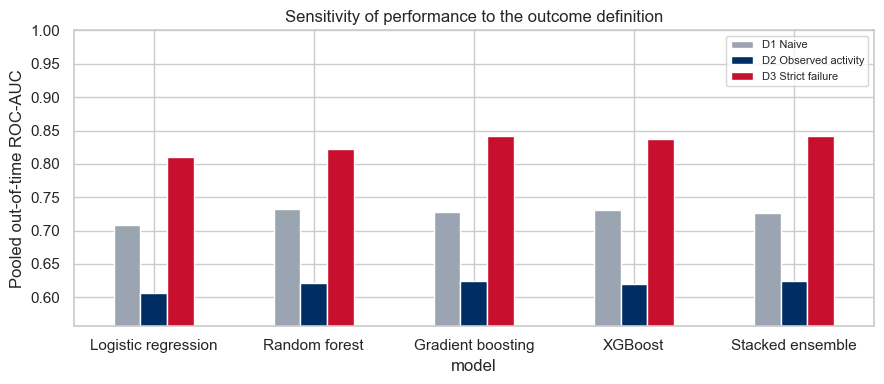

,D1 Naive,D2 Observed activity,D3 Strict failure
model,,,
Logistic regression,0.7077,0.6067,0.8106
Random forest,0.7330,0.6221,0.8222
Gradient boosting,0.7276,0.6252,0.8412
XGBoost,0.7308,0.6202,0.8373
Stacked ensemble,0.7266,0.6250,0.8423


In [31]:
sens = pooled.pivot(index="model", columns="definition", values="ROC-AUC").reindex(MODEL_NAMES)
sens.columns = [DEFS[c]["name"] for c in sens.columns]
ax = sens.plot(kind="bar", figsize=(9, 4), color=[GREY, NAVY, RED], rot=0)
ax.set(ylabel="Pooled out-of-time ROC-AUC", title="Sensitivity of performance to the outcome definition",
       ylim=(max(0.5, sens.values.min() - 0.05), 1))
ax.legend(fontsize=8)
savefig("07_auc_by_definition")
sens.round(4)

## 6. Interpretation with Shapley Additive Explanations (Objective iii)
### 6.1 Determinants of award (primary definition)

Exact TreeSHAP values are computed with XGBoost's built-in implementation (`pred_contribs=True`) for the model
trained on 2018–2023 and applied to 2024 tenders. One-hot columns are summed back to their original feature, and the
50 text components are grouped as *title text*.

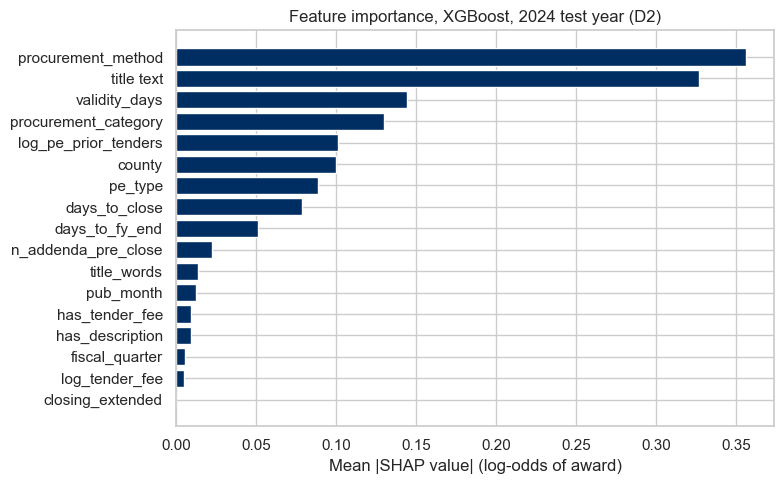

In [32]:
def base_feature(col):
    grp, name = col.split("__", 1)
    if grp == "txt":
        return "title text"
    if grp == "num":
        return name.replace("_missing", "")
    for c in sorted(CAT, key=len, reverse=True):
        if name.startswith(c + "_"):
            return c
    return name


def shap_by_feature(d, test_year=2024, sample=5000):
    keep_d, y_d = label(feat, d)
    tr = feat[keep_d & feat["year"].between(YEARS[0], test_year - 1)]
    te = feat[keep_d & (feat["year"] == test_year)].sample(min(sample, int((keep_d & (feat["year"] == test_year)).sum())), random_state=SEED)
    pre_s = make_preprocessor().fit(tr[X_COLS])
    model = clone(BASE_MODELS["XGBoost"][0]).set_params(**BEST_PARAMS["XGBoost"]).fit(pre_s.transform(tr[X_COLS]), y_d[tr.index])
    Xte = pre_s.transform(te[X_COLS])
    contrib = model.get_booster().predict(xgb.DMatrix(Xte), pred_contribs=True)[:, :-1]
    cols = pre_s.get_feature_names_out()
    sv = pd.DataFrame(contrib, columns=cols).T.groupby([base_feature(c) for c in cols]).sum().T
    return sv, te


shap_primary, te_shap = shap_by_feature(PRIMARY_DEF)
imp = shap_primary.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=NAVY)
ax.set(xlabel="Mean |SHAP value| (log-odds of award)", title=f"Feature importance, XGBoost, 2024 test year ({PRIMARY_DEF})")
savefig("08_shap_importance")

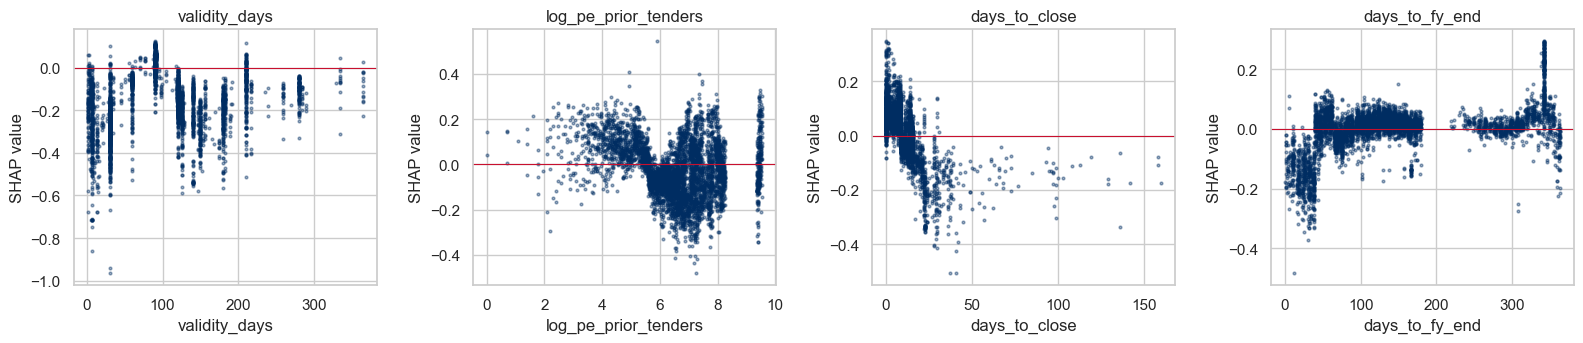

In [33]:
top_num = [f for f in imp.index[::-1] if f in NUM][:4]
fig, axes = plt.subplots(1, len(top_num), figsize=(4 * len(top_num), 3.6))
for ax, f in zip(np.atleast_1d(axes), top_num):
    ax.scatter(te_shap[f], shap_primary[f], s=4, alpha=0.4, color=NAVY)
    ax.axhline(0, color=RED, lw=0.8)
    ax.set(xlabel=f, ylabel="SHAP value", title=f)
savefig("09_shap_dependence")

### 6.2 Do the determinants change with the outcome definition?
Mean |SHAP| rankings are compared across D1–D3 with Spearman rank correlation. Low correlation would mean that
substantive conclusions about *what drives award* depend on how the outcome was labelled.

In [34]:
imp_by_def = pd.DataFrame({DEFS[d]["name"]: shap_by_feature(d)[0].abs().mean() for d in DEFS})
imp_by_def.to_csv(OUT_DIR / "shap_importance_by_definition.csv")
rank_corr = imp_by_def.corr(method="spearman")
display_cols = imp_by_def.rank(ascending=False).astype(int).sort_values(DEFS[PRIMARY_DEF]["name"])
print("Spearman rank correlation of feature importance between definitions:")
print(rank_corr.round(3).to_string())
print("\nImportance rank of each feature under each definition:")
display_cols

Spearman rank correlation of feature importance between definitions:
                      D1 Naive  D2 Observed activity  D3 Strict failure
D1 Naive                 1.000                 0.887              0.865
D2 Observed activity     0.887                 1.000              0.865
D3 Strict failure        0.865                 0.865              1.000

Importance rank of each feature under each definition:


,D1 Naive,D2 Observed activity,D3 Strict failure
procurement_method,1,1,1
title text,5,2,2
validity_days,4,3,7
procurement_category,8,4,10
log_pe_prior_tenders,2,5,4
county,6,6,6
pe_type,3,7,5
days_to_close,7,8,3
days_to_fy_end,9,9,9
n_addenda_pre_close,14,10,11


## 7. Fairness Audit (Objective iv)

The audit uses the selected model's pooled out-of-time predictions under the primary definition. The score is the
predicted probability of award; a tender is **flagged as at risk** when it falls below the model's threshold
(Ŷ = 0). Protected attributes are AGPO status *A* (tenders reserved under the AGPO scheme vs. not) and county.

| Criterion | Requirement | Measured here as |
|---|---|---|
| Independence | P(Ŷ=1 \| A=0) = P(Ŷ=1 \| A=1) | flag rate by group |
| Separation | P(Ŷ=1 \| Y=y, A=0) = P(Ŷ=1 \| Y=y, A=1) | false-flag rate among awarded tenders (1 − TPR) and FPR |
| Sufficiency | P(Y=1 \| S=s, A=0) = P(Y=1 \| S=s, A=1) | calibration by group; likelihood-ratio test of group terms |

The criteria generally cannot all hold when base rates differ between groups, so all three are reported.

In [35]:
F = (preds[(preds["definition"] == PRIMARY_DEF) & (preds["model"] == best)]
     .merge(feat[["id", "agpo", "county"]], on="id"))
F["flag"] = 1 - F["yhat"]


def group_table(df, by):
    g = df.groupby(by)
    out = pd.DataFrame({
        "tenders": g.size(),
        "base rate (award)": g["y"].mean(),
        "flag rate": g["flag"].mean(),
        "false-flag rate (awarded but flagged)": g.apply(lambda s: s.loc[s["y"] == 1, "flag"].mean()),
        "FPR (not awarded, predicted award)": g.apply(lambda s: s.loc[s["y"] == 0, "yhat"].mean()),
        "mean score": g["p"].mean(),
        "ECE": g.apply(lambda s: ece(s["y"], s["p"])),
    })
    return out


def ece(y, p, bins=10):
    b = np.minimum((np.asarray(p) * bins).astype(int), bins - 1)
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p), "b": b}).groupby("b")
    return float((d.size() / len(b) * (d["y"].mean() - d["p"].mean()).abs()).sum())


FA = F[F["agpo"] != "Unknown"]
agpo_tab = group_table(FA, "agpo")
agpo_tab.round(4)

,tenders,base rate (award),flag rate,false-flag rate (awarded but flagged),"FPR (not awarded, predicted award)",mean score,ECE
agpo,,,,,,,
AGPO,25558,0.8806,0.7184,0.7093,0.2150,0.8707,0.0530
Non-AGPO,60984,0.8151,0.7502,0.7286,0.1545,0.8506,0.0579


In [36]:
def boot_diff(df, stat, n_boot=N_BOOT):
    a, b = df[df["agpo"] == "AGPO"], df[df["agpo"] == "Non-AGPO"]
    point = stat(a) - stat(b)
    r = np.random.default_rng(SEED)
    draws = [stat(a.iloc[r.integers(0, len(a), len(a))]) - stat(b.iloc[r.integers(0, len(b), len(b))]) for _ in range(n_boot)]
    return point, *np.percentile(draws, [2.5, 97.5])


crit = {
    "Independence: flag rate": lambda s: s["flag"].mean(),
    "Separation: false-flag rate (Y=1)": lambda s: s.loc[s["y"] == 1, "flag"].mean(),
    "Separation: FPR (Y=0)": lambda s: s.loc[s["y"] == 0, "yhat"].mean(),
    "Sufficiency: ECE": lambda s: ece(s["y"], s["p"]),
}
fair_rows = []
for k, f in crit.items():
    pt, lo, hi = boot_diff(FA, f)
    fair_rows.append({"criterion (AGPO − Non-AGPO)": k, "difference": round(pt, 4), "95% CI": f"[{lo:.4f}, {hi:.4f}]",
                      "CI excludes 0": not (lo <= 0 <= hi)})

# chi-square test of independence between AGPO status and flagging
chi_p = chi2_contingency(pd.crosstab(FA["agpo"], FA["flag"]))[1]
# sufficiency: does AGPO status add information beyond the score? (likelihood-ratio test)
lg = np.log(np.clip(FA["p"], 1e-6, 1 - 1e-6) / (1 - np.clip(FA["p"], 1e-6, 1 - 1e-6)))
a_ = (FA["agpo"] == "AGPO").astype(float)
base_m = sm.Logit(FA["y"], sm.add_constant(pd.DataFrame({"logit": lg}))).fit(disp=0)
full_m = sm.Logit(FA["y"], sm.add_constant(pd.DataFrame({"logit": lg, "agpo": a_, "logit_x_agpo": lg * a_}))).fit(disp=0)
lr_stat = 2 * (full_m.llf - base_m.llf)
print(f"Independence chi-square test p = {chi_p:.3e}")
print(f"Sufficiency likelihood-ratio test (AGPO terms, df=2): LR = {lr_stat:.2f}, p = {chi2.sf(lr_stat, 2):.3e}")
pd.DataFrame(fair_rows)

Independence chi-square test p = 2.037e-22
Sufficiency likelihood-ratio test (AGPO terms, df=2): LR = 504.49, p = 2.827e-110


,criterion (AGPO − Non-AGPO),difference,95% CI,CI excludes 0
0,Independence: flag rate,-0.0318,"[-0.0383, -0.0255]",True
1,Separation: false-flag rate (Y=1),-0.0192,"[-0.0263, -0.0124]",True
2,Separation: FPR (Y=0),0.0606,"[0.0446, 0.0775]",True
3,Sufficiency: ECE,-0.0050,"[-0.0100, 0.0003]",False


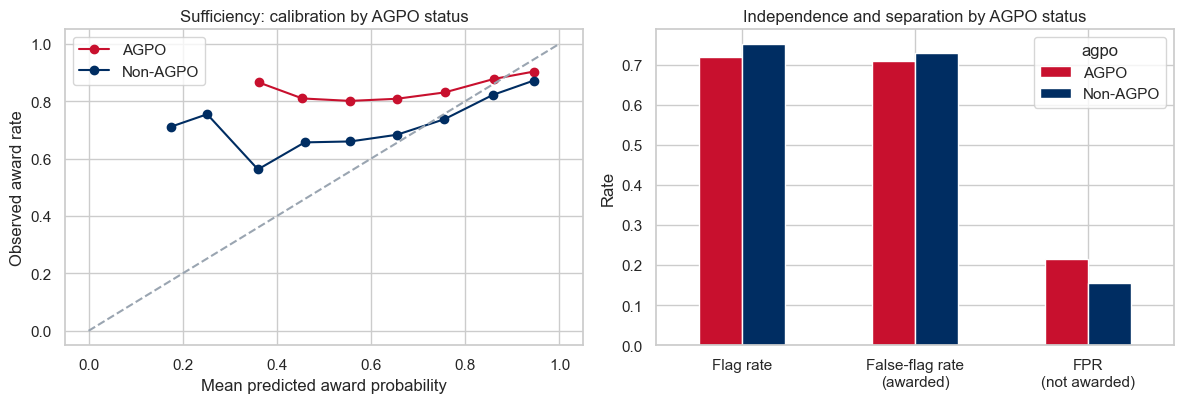

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cal = FA.assign(bin=np.minimum((FA["p"] * 10).astype(int), 9))
for grp, col in [("AGPO", RED), ("Non-AGPO", NAVY)]:
    c = cal[cal["agpo"] == grp].groupby("bin").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    c = c[c["n"] >= 30]
    axes[0].plot(c["p"], c["y"], marker="o", color=col, label=grp)
axes[0].plot([0, 1], [0, 1], ls="--", color=GREY)
axes[0].set(xlabel="Mean predicted award probability", ylabel="Observed award rate", title="Sufficiency: calibration by AGPO status")
axes[0].legend()
bars = agpo_tab[["flag rate", "false-flag rate (awarded but flagged)", "FPR (not awarded, predicted award)"]].T
bars.plot(kind="bar", ax=axes[1], color=[RED, NAVY], rot=0)
axes[1].set(title="Independence and separation by AGPO status", ylabel="Rate")
axes[1].set_xticklabels(["Flag rate", "False-flag rate\n(awarded)", "FPR\n(not awarded)"])
savefig("10_fairness_agpo")

### 7.2 County audit
Counties with at least 300 test-period tenders. Disparity is summarised by the range and the max/min ratio of each
rate across counties.

27 counties audited
                                          min     max  max/min ratio
flag rate                              0.2665  0.9860         3.6994
false-flag rate (awarded but flagged)  0.2599  0.9882         3.8029
ECE                                    0.0107  0.2270        21.1361


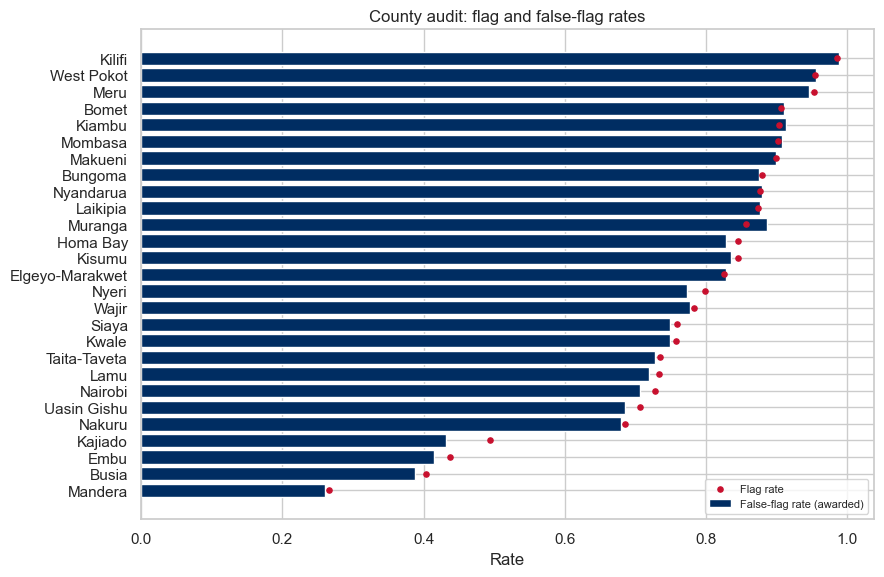

In [38]:
ct = group_table(F, "county")
ct = ct[ct["tenders"] >= 300].sort_values("flag rate")
summary = pd.DataFrame({
    "min": ct[["flag rate", "false-flag rate (awarded but flagged)", "ECE"]].min(),
    "max": ct[["flag rate", "false-flag rate (awarded but flagged)", "ECE"]].max()})
summary["max/min ratio"] = summary["max"] / summary["min"].replace(0, np.nan)
print(f"{len(ct)} counties audited")
print(summary.round(4).to_string())
fig, ax = plt.subplots(figsize=(9, max(4, len(ct) * 0.22)))
ax.barh(ct.index, ct["false-flag rate (awarded but flagged)"], color=NAVY, label="False-flag rate (awarded)")
ax.scatter(ct["flag rate"], ct.index, color=RED, s=14, zorder=3, label="Flag rate")
ax.set(xlabel="Rate", title="County audit: flag and false-flag rates")
ax.legend(loc="lower right", fontsize=8)
savefig("11_fairness_county")
ct.round(4).to_csv(OUT_DIR / "fairness_by_county.csv")

## 8. Deployment

The deployed model is retrained on every tender from 2018–2024 under the primary definition and saved as one bundle
with its preprocessor, threshold and risk bands. XGBoost is deployed when it is not significantly worse than the
selected model (DeLong p ≥ 0.05) or is itself the selected model, because it provides exact per-tender attributions
(TreeSHAP) for the "leading contributing features" the proposal's API returns.

In [39]:
xgb_vs_best = next((t for t in tests if t["comparison"].endswith("vs XGBoost")), None)
deploy_name = "XGBoost" if (best == "XGBoost" or float(xgb_vs_best["DeLong p"]) >= 0.05) else best
print("Selected model:", best, "| deployed model:", deploy_name)

keep_p, y_p = label(feat, PRIMARY_DEF)
train_all = feat[keep_p]
pre_final = make_preprocessor().fit(train_all[X_COLS])
X_all = pre_final.transform(train_all[X_COLS])
final_model = build_models(BEST_PARAMS)[deploy_name].fit(X_all, y_p[train_all.index])
risk_train = 1 - final_model.predict_proba(X_all)[:, 1]
bundle = {
    "preprocessor": pre_final, "model": final_model, "model_name": deploy_name,
    "threshold": THRESHOLDS[(PRIMARY_DEF, deploy_name)],
    "risk_band_cutoffs": {"High": float(np.quantile(risk_train, 0.8)), "Medium": float(np.quantile(risk_train, 0.5))},
    "feature_columns": X_COLS, "numeric": NUM, "categorical": CAT, "text": TEXT,
    "outcome_definition": DEFS[PRIMARY_DEF]["name"], "trained_on": f"{YEARS[0]}–{YEARS[1]}",
    "created": datetime.now().isoformat(timespec="seconds"),
}
joblib.dump(bundle, MODEL_DIR / "award_risk_bundle.joblib")
meta = {k: v for k, v in bundle.items() if k not in ("preprocessor", "model")}
meta["best_params"] = BEST_PARAMS[deploy_name] if deploy_name in BEST_PARAMS else "stacked"
(MODEL_DIR / "metadata.json").write_text(json.dumps(meta, indent=2, default=str))
print("Saved", MODEL_DIR / "award_risk_bundle.joblib")

Selected model: Gradient boosting | deployed model: Gradient boosting


Saved models\award_risk_v2\award_risk_bundle.joblib


In [40]:
def score_tenders(df, bundle, top_k=3):
    """Return award probability, risk band and leading contributing features for each tender."""
    X = bundle["preprocessor"].transform(df[bundle["feature_columns"]])
    p = bundle["model"].predict_proba(X)[:, 1]
    risk = 1 - p
    cut = bundle["risk_band_cutoffs"]
    band = np.where(risk >= cut["High"], "High", np.where(risk >= cut["Medium"], "Medium", "Low"))
    out = pd.DataFrame({"tender_id": df["id"].values, "award_probability": p.round(3), "risk_band": band})
    if bundle["model_name"] == "XGBoost":
        cols = bundle["preprocessor"].get_feature_names_out()
        contrib = bundle["model"].get_booster().predict(xgb.DMatrix(X), pred_contribs=True)[:, :-1]
        grouped = pd.DataFrame(contrib, columns=cols).T.groupby([base_feature(c) for c in cols]).sum().T
        out["leading_features"] = [", ".join(f"{f} ({v:+.2f})" for f, v in r.sort_values(key=abs, ascending=False).head(top_k).items())
                                   for _, r in grouped.iterrows()]
    return out


demo = feat[feat["year"] == 2024].sample(5, random_state=SEED)
score_tenders(demo, joblib.load(MODEL_DIR / "award_risk_bundle.joblib"))

,tender_id,award_probability,risk_band
0,203772,0.461,High
1,185439,0.487,High
2,206445,0.649,High
3,184759,0.754,High
4,198894,0.894,Medium


## 9. Summary of results
The cell below collects the headline numbers for the report. Interpretation belongs in the write-up; the figures
are saved in `outputs/award_notebook/figures/`.

In [41]:
prim = pooled[pooled["definition"] == PRIMARY_DEF].set_index("model")
print(f"Population: {len(feat):,} tenders ({YEARS[0]}–{YEARS[1]}); primary definition {DEFS[PRIMARY_DEF]['name']}")
print("Outcome classes:", feat["outcome_class"].value_counts().reindex(CLASSES).to_dict())
print(f"Selected model: {best}  pooled ROC-AUC {prim.loc[best, 'ROC-AUC']:.4f}, F1 (non-award) {prim.loc[best, 'F1 (non-award)']:.4f}")
print(f"Random-split optimism (XGBoost): {auc_random - auc_temporal.mean():+.4f} AUC")
print("ROC-AUC by definition (selected model):", sens.loc[best].round(4).to_dict())
print("Spearman correlation of feature rankings, D1 vs D2:", round(rank_corr.iloc[0, 1], 3), "| D2 vs D3:", round(rank_corr.iloc[1, 2], 3))
print("AGPO fairness (AGPO − Non-AGPO):")
for r in fair_rows:
    print(f"  {r['criterion (AGPO − Non-AGPO)']}: {r['difference']:+.4f} {r['95% CI']}")

Population: 189,980 tenders (2018–2024); primary definition D2 Observed activity
Outcome classes: {'Awarded': 92013, 'Terminated': 4723, 'Undetermined': 11791, 'No recorded activity': 81453}
Selected model: Gradient boosting  pooled ROC-AUC 0.6252, F1 (non-award) 0.3090
Random-split optimism (XGBoost): +0.1529 AUC
ROC-AUC by definition (selected model): {'D1 Naive': 0.7276, 'D2 Observed activity': 0.6252, 'D3 Strict failure': 0.8412}
Spearman correlation of feature rankings, D1 vs D2: 0.887 | D2 vs D3: 0.865
AGPO fairness (AGPO − Non-AGPO):
  Independence: flag rate: -0.0318 [-0.0383, -0.0255]
  Separation: false-flag rate (Y=1): -0.0192 [-0.0263, -0.0124]
  Separation: FPR (Y=0): +0.0606 [0.0446, 0.0775]
  Sufficiency: ECE: -0.0050 [-0.0100, 0.0003]
